# Exclusive J/ψ Photoproduction in p+p Collisions at √s = 510 GeV

## Sartre 2 simulation

**Author**: **Štěpán Skalka**  
*Faculty of Nuclear Sciences and Physical Engineering, Czech Technical University in Prague*

---

### What are we doing here?
In Ultra-Peripheral proton-proton Collisions ($p+p$ UPCs) at the Relativistic Heavy Ion Collider (RHIC, $\sqrt{s} = 510\text{ GeV}$), exclusive $J/\psi$ vector meson photoproduction proceeds via:

$$
p + p \longrightarrow p + J/\psi(\rightarrow e^+e^-) + p
$$

In previous experimental analysis (Diploma thesis of Michal Vranovský) of the STAR Run 17 dataset without Roman Pot forward proton tagging (that means only using the central detector, electron kinematic **Cut C5**: $|\eta_e| < 0.9$) the measured cross section was:

$$
\sigma_{\text{STAR}}^{\text{no RP}} = 650 \pm 40\text{ (stat)}^{+70}_{-50}\text{ (sys)}\text{ pb}, \qquad \frac{d\sigma_{\text{STAR}}^{\text{no RP}}}{dy} = 360 \pm 20\text{ (stat)}^{+40}_{-30}\text{ (sys)}\text{ pb}
$$

Requiring, in addition, exactly one forward scattered proton reconstructed inside the acceptance of the Roman Pot detectors (Cut F1 & F2), gave:

$$
\sigma_{\text{STAR}}^{\text{with RP}} = 77 \pm 5\text{ (stat)}^{+9}_{-7}\text{ (sys)}\text{ pb}, \qquad \frac{d\sigma_{\text{STAR}}^{\text{with RP}}}{dy} = 43 \pm 3\text{ (stat)}^{+5}_{-4}\text{ (sys)}\text{ pb}
$$

However, the Monte Carlo generator **STARlight** predicted only:

$$
\sigma_{\text{STARlight}} = 40.0\text{ pb}
$$

This means **16.25-fold discrepancy** in compairson to the central detector measurements. STARlight severely underestimates the experimental cross section. Moreover it is unable to provide proton kinemaics and therefore cannot be used to compare the Roman Pot cross section.

To investigate, we use the **Sartre 2** Monte Carlo generator, which implements the **QCD Color Dipole Model**:
- **`bSat` (IPsat model):** Includes non-linear gluon saturation ($gg \rightarrow g$ recombination) at high gluon density via dipole-proton scattering amplitude (see Sartre documentation for details):

  $$
  \frac{d\sigma_{q\bar{q}}}{d^2b} = 2\left[1 - \exp\left(-\frac{\pi^2}{2N_c} r^2 \alpha_s(\mu^2) xg(x, \mu^2) T_p(b)\right)\right]
  $$

- **`bNonSat` (IPnonsat / Linear model):** Uses the linear single-Pomeron exchange approximation without saturation:

  $$
  \frac{d\sigma_{q\bar{q}}}{d^2b} = \frac{\pi^2}{N_c} r^2 \alpha_s(\mu^2) xg(x, \mu^2) T_p(b)
  $$

We simulate $100{,}000$ events here and:
1. Document the complete Sartre 2 simulation setup
2. Plot various kinematics of the $J/\psi$, the daughter $e^+e^-$ pair, and outgoing protons (the photon emitter $p_\gamma$ and the pomeron target $p_{\mathbb{P}}$).
3. Apply STAR central ($|\eta_e| < 0.9$) and Roman Pot fiducial $(p_x, p_y)$ cuts to determine the fraction of events captured by the Roman Pots and compare obtained cross sections with the STAR measurement.


## Simulation Setup

We are using neewest version of Sartre (2.20). For the instalation details check the readme in github repo and/or the Sartre documentation. 

First we have to write a simple C++ driver program (`simulation/sartre_pp_jpsi.cxx`):**. Sartre 2 is a C++ library (`libsartre.so`), not a standalone compiled executable. So we have to compile the simulation driver and then pass simulation parameters as a runcard and/or command-line arguments. 

**Runcard (`simulation/runcard_bSat_HMPZ.txt`)** is a plain-text configuration file specifying the various simulation parameters auch as beam energies ($255\text{ GeV}$ on $255\text{ GeV}$), dipole model (`bSat` or `bNonSat`), vector meson ID (`443` for $J/\psi$), etc.

To run the simulation with a runcard it is best to use some kind of wrapper script. Here we have **Parallel Python Runner (`scripts/run_parallel_sartre.py`)**. Because generating $100{,}000$ events on a single core takes significant ammount of time, this Python wrapper splits the job across multiple CPU cores with independent random seeds and merges the output `.root` files using ROOT's `hadd`.

### Issues Encountered 
Before we could generate our production datasets, we had to diagnose and fix three bugs in the upstream Sartre 2.20 codebase (all patches are stored in `sartre2_modern_gcc_patches.patch`):

1. **Modern GCC 15 / C++23 Compilation Errors:**
   Upstream Sartre 2.20 was written for older C++17 compilers. On modern Linux with GCC 15 (which defaults to C23 and C++23), compilation failed because Cuba 4.2.2 attempted to `typedef enum { false, true } bool;` (now a reserved keyword in C23), `cuba/makefile.in` had a parallel `make -j` archive race condition, and `Settings.cpp` / `TableGeneratorSettings.cpp` were missing explicit `#include <cmath>` and `#include <algorithm>` headers. Adding header guards, `.NOTPARALLEL:`, and the missing STL includes resolved all build errors.
2. **The Unphysical `xpom = 0.62` Lookup Table Crash:**
   In symmetric $p+p$ collisions, Sartre evaluates the cross section for both beam directions: Direction 1 (Proton 1 emits $\gamma$, Proton 2 exchanges $\mathbb{P}$ at momentum fraction $x_{\mathbb{P},+}$) and Direction 2 (Proton 2 emits $\gamma$, Proton 1 exchanges $\mathbb{P}$ at $x_{\mathbb{P},-}$). When a $J/\psi$ is produced at forward rapidity, Direction 1 requires a tiny momentum fraction $x_{\mathbb{P},+} \approx 6 \times 10^{-5}$, which is well inside Sartre's precomputed dipole lookup tables ($x_{\mathbb{P}} \in [10^{-6}, 0.02]$). However, producing that same forward $J/\psi$ from Direction 2 would require the opposite proton to lose **62% of its momentum** ($x_{\mathbb{P},-} \approx 0.62$). Physically, diffractive Pomeron exchange cannot occur at $x_{\mathbb{P}} = 0.62$—the cross section for Direction 2 at that rapidity is zero. Upstream Sartre queried the lookup table for `xpom = 0.62` without checking the table boundary ($x_{\max} = 0.02$), causing `TableCollection::get()` to assume table files were missing and abort after 10 warnings. We patched `CrossSection.cpp` and `TableCollection.cpp` to check `minX()..maxX()` and `minT()..maxT()` first and return `0` whenever a kinematic point lies outside the physical table range.
3. **The 4-Hour Startup Freeze in `Sartre::init()`:**
   During initialization, Sartre searches for the maximum of the probability density function using `BrentMinimizer1D` and runs a "burn-in" loop for the UnuRan sampler. Upstream set the grid search to `SetNpx(100000)` points followed by `1,000` burn-in events. In Sartre 2, each evaluation performs 2D Fast Fourier Transforms taking $\sim 0.15\text{ s}$, meaning $100{,}000 \times 0.15\text{ s} \approx 4.2\text{ hours}$ before event 1 was generated. Because the UPC cross-section surface is smooth, changing `SetNpx` to `40` and burn-in to `10` reduced startup time from $>4\text{ hours}$ to $\approx 6\text{ seconds}$ while finding the exact same maximum.

   ---

## C++ Simulation Driver Code

Below is the complete C++ driver (`simulation/sartre_pp_jpsi.cxx`) used to generate the data:

```cpp
//==============================================================================
//  sartre_pp_jpsi.cxx
//  Monte Carlo Simulation Driver for Exclusive J/psi Photoproduction in p+p
//  Reaction: p + p -> p + J/psi + p (with J/psi -> e+ e-) at sqrt(s) = 510 GeV
//==============================================================================

#include <iostream>
#include <cmath>
#include <string>
#include <utility>

// ROOT headers
#include "TFile.h"
#include "TTree.h"
#include "TH1D.h"
#include "TLorentzVector.h"
#include "TRandom3.h"

// Sartre 2 headers
#include "Sartre.h"
#include "Settings.h"
#include "Event.h"
#include "TwoBodyVectorMesonDecay.h"

using namespace std;

//------------------------------------------------------------------------------
// Helper Struct: ParticleBranch
// Purpose: Avoids declaring 9 separate doubles and 9 tree->Branch() calls for
//          every single particle. Creates the exact same flat branches in the
//          ROOT TTree (e.g., "jpsi_px", "jpsi_pt", etc.) automatically.
//------------------------------------------------------------------------------
struct ParticleBranch {
    double px = 0, py = 0, pz = 0, E = 0;
    double pt = 0, eta = 0, phi = 0, m = 0, y = 0;

    // Register branches in the TTree with a given prefix (e.g. "jpsi", "em")
    void bindToTree(TTree* tree, const string& prefix, bool includeRapidity = false) {
        tree->Branch((prefix + "_px").c_str(),  &px,  (prefix + "_px/D").c_str());
        tree->Branch((prefix + "_py").c_str(),  &py,  (prefix + "_py/D").c_str());
        tree->Branch((prefix + "_pz").c_str(),  &pz,  (prefix + "_pz/D").c_str());
        tree->Branch((prefix + "_E").c_str(),   &E,   (prefix + "_E/D").c_str());
        tree->Branch((prefix + "_pt").c_str(),  &pt,  (prefix + "_pt/D").c_str());
        tree->Branch((prefix + "_eta").c_str(), &eta, (prefix + "_eta/D").c_str());
        tree->Branch((prefix + "_phi").c_str(), &phi, (prefix + "_phi/D").c_str());
        tree->Branch((prefix + "_m").c_str(),   &m,   (prefix + "_m/D").c_str());
        if (includeRapidity) {
            tree->Branch((prefix + "_y").c_str(), &y, (prefix + "_y/D").c_str());
        }
    }

    // Extract kinematics from a ROOT TLorentzVector
    void fillFrom(const TLorentzVector& v) {
        px  = v.Px();
        py  = v.Py();
        pz  = v.Pz();
        E   = v.E();
        pt  = v.Pt();
        // Protect against division-by-zero in pseudorapidity when pT is ~0
        eta = (pt > 1e-6) ? v.Eta() : 999.0;
        phi = v.Phi();
        m   = v.M();
        y   = v.Rapidity();
    }
};

//------------------------------------------------------------------------------
// Function: applyRandomBeamReversal
// Purpose:  Sartre assumes asymmetric collisions where Beam 1 (+z) ALWAYS emits
//           the photon and Beam 2 (-z) is ALWAYS the Pomeron target.
//           In symmetric p+p collisions, either proton has a 50% chance to emit
//           the photon. We restore this symmetry by randomly rotating 50% of
//           the events by 180 degrees (pi radians) around the x-axis, which
//           flips Pz -> -Pz (rapidity y -> -y) and Py -> -Py.
//------------------------------------------------------------------------------
bool applyRandomBeamReversal(Event* event) {
    TRandom3* rnd = EventGeneratorSettings::randomGenerator();
    if (rnd->Uniform(1.0) > 0.5) {
        for (size_t i = 0; i < event->particles.size(); ++i) {
            event->particles[i].p.RotateX(M_PI);
        }
        return true;
    }
    return false;
}

//------------------------------------------------------------------------------
// Main Simulation Driver
//------------------------------------------------------------------------------
int main(int argc, char* argv[]) {
    // 1. Parse Command-Line Arguments
    // Only <runcard.txt> is required. Everything else is optional and overrides
    // the settings inside the runcard (used when running parallel worker chunks).
    if (argc < 2 || argc > 6) {
        cout << "Usage: " << argv[0] << " <runcard.txt> [output.root] [nEvents] [seed] [known_cs_nb]\n";
        return 1;
    }

    string runcard          = argv[1];
    string rootfile         = (argc >= 3) ? argv[2] : "";
    unsigned long cmdEvents = (argc >= 4) ? stoul(argv[3]) : 0;
    unsigned int  cmdSeed   = (argc >= 5) ? stoul(argv[4]) : 0;
    double cmdCrossSection  = (argc >= 6) ? stod(argv[5])  : 0.0;

    // 2. Initialize Sartre with the runcard
    Sartre sartre;
    if (!sartre.init(runcard)) {
        cerr << "ERROR: Sartre failed to initialize runcard: " << runcard << endl;
        return 1;
    }

    EventGeneratorSettings* settings = sartre.runSettings();

    // Apply command-line overrides (if provided by the parallel Python runner)
    if (cmdSeed > 0) {
        settings->setSeed(cmdSeed);
        EventGeneratorSettings::randomGenerator()->SetSeed(cmdSeed);
    }
    if (rootfile.empty()) rootfile = settings->rootfile();
    if (rootfile.empty()) rootfile = "sartre_out.root";

    unsigned long nEventsRequested = (cmdEvents > 0) ? cmdEvents : settings->numberOfEvents();

    // Read decay daughter PDG ID from runcard's `userInt` (default to 11 = electron)
    int daughterID = (settings->userInt() != 0) ? settings->userInt() : 11;

    cout << "==========================================================\n"
         << "  Runcard:          " << runcard << "\n"
         << "  Output ROOT file: " << rootfile << "\n"
         << "  Events to run:    " << nEventsRequested << "\n"
         << "  Decay PDG ID:     " << daughterID << "\n"
         << "==========================================================" << endl;

    // 3. Create Output ROOT File and TTree
    TFile* outFile = new TFile(rootfile.c_str(), "RECREATE");
    if (!outFile || outFile->IsZombie()) {
        cerr << "ERROR: Cannot create output ROOT file: " << rootfile << endl;
        return 1;
    }

    TTree* tree = new TTree("sartre_tree", "Sartre Exclusive J/psi Photoproduction in p+p");

    // Event-level kinematic variables
    int    iEvent_val = 0, pol_val = 0, dmode_val = 0, is_reversed = 0;
    double t_val = 0, Q2_val = 0, W_val = 0, x_val = 0, y_val = 0, s_val = 0, xpom_val = 0;

    tree->Branch("iEvent",      &iEvent_val,  "iEvent/I");
    tree->Branch("t",           &t_val,       "t/D");        // Momentum transfer squared at proton vertex (GeV^2)
    tree->Branch("Q2",          &Q2_val,      "Q2/D");       // Photon virtuality (GeV^2)
    tree->Branch("W",           &W_val,       "W/D");        // Photon-proton center-of-mass energy (GeV)
    tree->Branch("x",           &x_val,       "x/D");        // Bjorken-x
    tree->Branch("y",           &y_val,       "y/D");        // Photon inelasticity
    tree->Branch("s",           &s_val,       "s/D");        // Total p+p center-of-mass energy squared (GeV^2)
    tree->Branch("xpom",        &xpom_val,    "xpom/D");     // Pomeron momentum fraction
    tree->Branch("pol",         &pol_val,     "pol/I");      // Photon polarization: 0 = T, 1 = L
    tree->Branch("dmode",       &dmode_val,   "dmode/I");    // Diffractive mode: 0 = coherent, 1 = incoherent
    tree->Branch("is_reversed", &is_reversed, "is_reversed/I"); // 1 if beams were flipped (+z <-> -z)

    // Particle branches using our helper struct
    ParticleBranch b_jpsi, b_em, b_ep, b_p_gamma, b_p_pom;
    b_jpsi.bindToTree(tree,    "jpsi",    true);  // J/psi (includes rapidity jpsi_y)
    b_em.bindToTree(tree,      "em",      false); // Daughter electron (e-)
    b_ep.bindToTree(tree,      "ep",      false); // Daughter positron (e+)
    b_p_gamma.bindToTree(tree, "p_gamma", false); // Scattered proton that emitted the photon
    b_p_pom.bindToTree(tree,   "p_pom",   false); // Scattered proton that exchanged the Pomeron

    // Reconstructed e+e- pair and transverse momentum balance variables
    double pair_m = 0, pair_pt = 0, pair_y = 0, pair_eta = 0;
    double pt_missing_pom = 0, pt_missing_gamma = 0, pt_balance = 0;

    tree->Branch("pair_m",           &pair_m,           "pair_m/D");
    tree->Branch("pair_pt",          &pair_pt,          "pair_pt/D");
    tree->Branch("pair_y",           &pair_y,           "pair_y/D");
    tree->Branch("pair_eta",         &pair_eta,         "pair_eta/D");
    tree->Branch("pt_missing_pom",   &pt_missing_pom,   "pt_missing_pom/D");
    tree->Branch("pt_missing_gamma", &pt_missing_gamma, "pt_missing_gamma/D");
    tree->Branch("pt_balance",       &pt_balance,       "pt_balance/D");

    // 4. Main Event Generation Loop
    TwoBodyVectorMesonDecay decayEngine;
    unsigned long nValidEvents = 0;
    unsigned long printStep = max(1UL, min(100UL, nEventsRequested / 100));

    // How Sartre's `event->particles` array is structured:
    //   Index 0: Incoming Beam 1 proton (+z)
    //   Index 1: Incoming Beam 2 proton (-z)
    //   Index 2: Outgoing proton from photon vertex (very small pT, stays in beam pipe)
    //   Index 3: Virtual photon (gamma*)
    //   Index 4: Produced Vector Meson (J/psi)
    //   Index 5: Pomeron (IP)
    //   Index 6: Outgoing proton from Pomeron vertex (higher pT, measured in Roman Pots)
    for (unsigned long iEvt = 0; iEvt < nEventsRequested; ++iEvt) {
        Event* event = sartre.generateEvent();
        if (!event) continue;

        // Symmetrize identical p+p beams (50% chance to flip z-axis)
        bool rev = (settings->UPC() && settings->A() == settings->UPCA())
                   ? applyRandomBeamReversal(event) : false;

        TLorentzVector vm     = event->particles[4].p; // J/psi
        TLorentzVector pGamma = event->particles[2].p; // Photon-emitting proton
        TLorentzVector pPom   = event->particles[6].p; // Pomeron-target proton

        // Sanity check: skip event if J/psi 4-momentum has NaN or negative energy
        if (vm.E() <= 0 || vm.M() <= 0 || !isfinite(vm.E())) continue;

        // Decay J/psi -> e- (d1) + e+ (d2) preserving helicity polarization
        pair<TLorentzVector, TLorentzVector> daughters = decayEngine.decayVectorMeson(vm, *event, daughterID);
        TLorentzVector d1   = daughters.first;
        TLorentzVector d2   = daughters.second;
        TLorentzVector pair = d1 + d2;

        // Fill event-level variables
        iEvent_val  = event->eventNumber;
        t_val       = event->t;
        Q2_val      = event->Q2;
        W_val       = event->W;
        x_val       = event->x;
        y_val       = event->y;
        s_val       = event->s;
        xpom_val    = event->xpom;
        pol_val     = (event->polarization == transverse) ? 0 : 1;
        dmode_val   = (event->diffractiveMode == coherent) ? 0 : 1;
        is_reversed = rev ? 1 : 0;

        // Fill particle kinematics using our helper struct
        b_jpsi.fillFrom(vm);
        b_em.fillFrom(d1);
        b_ep.fillFrom(d2);
        b_p_gamma.fillFrom(pGamma);
        b_p_pom.fillFrom(pPom);

        // Fill reconstructed pair kinematics
        pair_m   = pair.M();
        pair_pt  = pair.Pt();
        pair_y   = pair.Rapidity();
        pair_eta = pair.Eta();

        // Fill transverse momentum balance checks:
        // In an exclusive reaction p+p -> p + J/psi + p, total transverse momentum is zero:
        //   vec(pT_J/psi) + vec(pT_p_pom) + vec(pT_p_gamma) = 0
        // If only the Roman Pot proton (p_pom) is detected, the missing pT equals p_gamma's pT:
        pt_missing_pom   = (vm + pPom).Pt();
        pt_missing_gamma = (vm + pGamma).Pt();
        pt_balance       = (vm + pPom + pGamma).Pt(); // Should be ~0 (numerical precision check)

        tree->Fill();
        nValidEvents++;

        if ((iEvt + 1) % printStep == 0 || (iEvt + 1) == nEventsRequested) {
            cout << "Processed " << (iEvt + 1) << " / " << nEventsRequested << " events..." << endl;
        }
    }

    // 5. Compute or Use Precomputed Total Cross Section (known_cs_nb)
    // If a known cross section was explicitly provided via argv[5] (cmdCrossSection > 0.0),
    // use it directly. Otherwise, compute it dynamically via Sartre's totalCrossSection().
    double totalCrossSection_nb = 0.0;
    if (cmdCrossSection > 0.0) {
        totalCrossSection_nb = cmdCrossSection;
    } else {
        cout << "Calculating total cross section via Sartre phase-space integration..." << endl;
        totalCrossSection_nb = sartre.totalCrossSection();
    }

    cout << "Finished! Valid Events: " << nValidEvents
         << " | Cross Section: " << totalCrossSection_nb << " nb\n";

    // 6. Save Metadata Histogram (Cross Section & Event Count)
    // NOTE ON PARALLEL MERGING (`hadd`):
    // When `hadd` merges N worker files, it sums the bins of all histograms!
    //   - Bin 2 (nEvents) will correctly equal the sum of all events across all workers.
    //   - Bin 1 (sigma_total_nb) will be summed N times (N_workers * sigma_total_nb)!
    TH1D* hSummary = new TH1D("histoForCSandNumberOfEvents", "Cross section (nb) and event count", 2, 0, 2);
    hSummary->SetBinContent(1, totalCrossSection_nb);
    hSummary->SetBinContent(2, (double)nValidEvents);
    hSummary->GetXaxis()->SetBinLabel(1, "sigma_total_nb");
    hSummary->GetXaxis()->SetBinLabel(2, "nEvents");

    tree->Write();
    hSummary->Write();
    outFile->Close();

    return 0;
}
```

### Details
1**Sartre Particle Indexing (`event->particles`):**
   In Sartre 2, particle positions in the event record are fixed:
   - Index `0`: Incoming Beam 1 proton moving along $+z$.
   - Index `1`: Incoming Beam 2 proton moving along $-z$.
   - Index `2`: Outgoing photon-emitting proton $p_\gamma$. In Ultra-Peripheral Collisions ($Q^2 \approx 0$), this proton receives negligible transverse momentum ($p_T < 10^{-13}\text{ GeV}/c$) and stays inside the LHC/RHIC beam pipe.
   - Index `3`: Exchanged quasi-real virtual photon $\gamma^*$.
   - Index `4`: Produced vector meson ($J/\psi$, PDG ID 443).
   - Index `5`: Diffractive Pomeron exchange $\mathbb{P}$.
   - Index `6`: Outgoing Pomeron-scattered target proton $p_{\mathbb{P}}$. This proton receives a substantial transverse momentum kick $\sqrt{|t|} \sim 0.4\text{--}0.5\text{ GeV}/c$, allowing it to deflect out of the beam pipe and enter the acceptance of the forward Roman Pot silicon detectors.
**Symmetrizing Identical Protons (`applyRandomBeamReversal`):**
   Sartre natively models an asymmetric system (such as electron-proton or electron-ion) where Beam 1 ($+z$) is always the projectile and Beam 2 ($-z$) is always the target. In symmetric $p+p$ collisions, both protons are identical and either has an equal $50\%$ probability of emitting the photon. The driver calls `applyRandomBeamReversal()`, which draws a uniform random number and, with $50\%$ probability, rotates all 4-momenta by $\pi$ radians around the $x$-axis (`RotateX(M_PI)`). This transformation flips $(p_x, p_y, p_z) \rightarrow (p_x, -p_y, -p_z)$, exactly inverting laboratory rapidity $y \rightarrow -y$ while preserving physical invariant masses, cross sections, and helicities.


### Compilation
The simulation driver is compiled against ROOT 6.40, Pythia 8.318, and Sartre 2.20 using the following command:

```bash
source .venv/bin/activate

g++ -O3 -std=c++23 simulation/sartre_pp_jpsi.cxx \
    -I$SARTRE_DIR/include \
    -I$ROOTSYS/include \
    -I$PYTHIA8/include \
    -L$SARTRE_DIR/lib -lsartre -lgemini -lcuba \
    -L$PYTHIA8/lib -lpythia8 \
    -L$ROOTSYS/lib $(root-config --cflags --libs) -lEG -lMathMore -lUnuran \
    -lgsl -lgslcblas \
    -o simulation/sartre_pp_jpsi
```

---


## Runcard

Below is the used runcard `simulation/runcard_bSat_HMPZ.txt`: 

```ini
#==============================================================================
# Sartre UPC Runcard: bSat (IPsat) with HMPZ Parameter Set
# System: p + p -> p + J/psi + p @ sqrt(s) = 510 GeV
# Decay:  J/psi -> e+ e- (userInt = 11)
#==============================================================================

# --- Beam & Collision System Kinematics ---
eBeamEnergy = 255.0       # Energy of Beam 1 (GeV). In UPC, this is the proton acting as photon source.
hBeamEnergy = 255.0       # Energy of Beam 2 (GeV), the hadron target proton (sqrt(s) = 2 * 255 = 510 GeV).
A = 1                     # Mass number of hadron target (A = 1 for proton).
UPCA = 1                  # Mass number of projectile emitting the quasi-real photon (UPCA = 1 for proton).
UPC = true                # Enables Ultra-Peripheral Collision mode 

# --- Event Generation Volume & Verbosity ---
numberOfEvents = 100000   # Default number of events to simulate (can be overridden via command line).
timesToShow = 10          # Progress update frequency during table initialization.
verbose = false           # Suppresses verbose generator debug logs.
verboseLevel = 1          # Verbosity level (0 = quiet, 1 = informative, 2 = debug).

# --- Output Storage ---
rootfile = data/sartre_bSat_100k.root   # Default target ROOT output file.

# --- Microscopic Physics Model ---
dipoleModel = bSat                  # Color dipole model: 'bSat' (IPsat gluon saturation) or 'bNonSat' (linear DGLAP).
dipoleModelParameterSet = HMPZ      # Parameter fit: 'HMPZ' (Kowalski, Motyka, Watt 2006) or 'STU'.
vectorMesonId = 443                 # PDG Monte Carlo particle code (443 = J/psi vector meson).
tableSetType = total_and_coherent   # Dipole amplitude table lookup mode.

# --- Vector Meson Decay Channel ---
userInt = 11              # User flag passed to decay engine: 11 = electron (decays J/psi -> e+ e-).

# --- Quantum Mechanical & Amplitude Corrections ---
correctForRealAmplitude = true      # Incorporates real-to-imaginary amplitude ratio via dispersion relations.
correctSkewedness = true            # Applies off-forward gluon skewedness factor Rg for unequal x and x'.
maxLambdaUsedInCorrections = 0.1    # Upper bound on gluon anomalous dimension exponent lambda.

# --- Nuclear & Electromagnetic Engines ---
enableNuclearBreakup = false        # Gemini breakup engine (false for proton targets A = 1).
applyPhotonFlux = true              # Applies the Weizsaecker-Williams photon flux of the relativistic proton.
seed = 20261025                     # Base pseudo-random generator seed (TRandom3).
```

### Parameter Explanations & Physical Motivation

| Parameter | Configured Value |  |
| :--- | :--- | :--- |
| `eBeamEnergy` | `255.0` | Beam 1 proton energy ($255\text{ GeV}$). In UPC photoproduction, Beam 1 serves as the photon emitter. |
| `hBeamEnergy` | `255.0` | Beam 2 proton energy ($255\text{ GeV}$). Target hadron proton, giving center-of-mass energy $\sqrt{s} = 2\sqrt{E_1 E_2} = 510\text{ GeV}$. |
| `A` | `1` | Mass number of hadron target ($A=1$ for proton). |
| `UPCA` | `1` | Mass number of projectile emitting the photon ($UPCA=1$ for proton). |
| `UPC` | `true` | Enables Ultra-Peripheral Collision mode. |
| `numberOfEvents`| `100000` | Simulates $100{,}000$ events. |
| `dipoleModel` | `bSat` / `bNonSat` | Chooses between the saturation model (`bSat` / IPsat) and the linearised model (`bNonSat` / IPnonsat). |
| `dipoleModelParameterSet` | `HMPZ` | HERA measurements dipole parameter fit. |
| `vectorMesonId` | `443` | PDG particle ID for the ground-state charmonium vector meson $J/\psi(1S)$.|
| `tableSetType` | `total_and_coherent`| Loads both coherent (intact proton) and total (coherent + proton dissociation) diffractive cross-section tables. |
| `userInt` | `11` | Custom integer flag read by C++ driver to select the decay daughter PDG ID (`11` = $e^- / e^+$ for $J/\psi \rightarrow e^+e^-$). |
| `correctForRealAmplitude` | `true` | Accounts for the real part of the diffractive scattering amplitude via dispersion relations, increases cross sections by $\sim 10\text{--}15\%$. |
| `correctSkewedness` | `true` | Applies the Shuvaev off-forward gluon skewedness factor $R_g(\lambda)$ to account for unequal gluon momentum fractions ($x \neq x'$), increases cross sections by $\sim 30\text{--}40\%$. |
| `maxLambdaUsedInCorrections` | `0.1` | Upper bound capping the effective anomalous dimension derivative $\lambda = \partial\ln\mathcal{A}/\partial\ln(1/x_{\mathbb{P}})$ to prevent divergences near table boundaries. |
| `enableNuclearBreakup` | `false` | Disables the Gemini nuclear decay engine because the target is an individual proton ($A=1$). |
| `applyPhotonFlux` | `true` | Applies the Weizsäcker-Williams photon flux of the ultra-relativistic proton. |
| `seed` | `20261025` | Base seed initializing the ROOT `TRandom3` pseudo-random engine. |

## Parallel Execution Script

Because generating $100{,}000$ events on a single CPU core requires 20ish hours of computation, the Python script `scripts/run_parallel_sartre.py` parallelizes generation across multiple CPU cores:
- It splits the requested number of events equally across $N_{\text{workers}}$ CPU cores (default 12 cores, $N_{\text{cores}} - 2$).
- Assigns each worker an independent seed:

  $$
  \text{Seed}_k = \text{BaseSeed} + 100 \times k
  $$

- Workers are executed under `nice -n 10` priority and capped at $N_{\text{cores}} - 2$ threads, since I want it to be nice to my system and I don't have a fire extinguisher on hand.
- All worker files (`data/chunks/chunk_<runcard>_*.root`) are merged into the final ROOT file using ROOT's `hadd -f` and then cleaned up automatically.

### Command-Line Usage Examples
```bash
# Example 1: Interactive mode with Tab autocompletion
python3 scripts/run_parallel_sartre.py

# Example 2: Run with bSat runcard across 12 cores for 100,000 events
python3 scripts/run_parallel_sartre.py simulation/runcard_bSat_HMPZ.txt -w 12 -e 100000

# Example 3: Run bNonSat with precomputed cross section to skip lengthy integration
python3 scripts/run_parallel_sartre.py simulation/runcard_bNonSat_HMPZ.txt -w 12 -e 100000 --cs 39.2815
```

### The `hadd` Cross-Section Normalization Rule
In Sartre's C++ driver, each worker writes the total integrated cross section $\sigma_{\text{tot}}$ into **Bin 1** of `histoForCSandNumberOfEvents` and its chunk event count into **Bin 2**. When ROOT's `hadd` merges $N_{\text{workers}}$ files, it sums all histogram bins across all input files:
- **Bin 2 (Number of Events):** Sums to $\sum_k N_k = N_{\text{total}} = 100{,}000$ events.
- **Bin 1 (Total Cross Section):** Sums to $N_{\text{workers}} \times \sigma_{\text{tot}}$.

Because each worker calls `SetBinContent` twice, each worker produces `fEntries = 2`. In an unpatched merged file from $N_{\text{workers}}$ workers, `fEntries = 2 * N_workers`. We therefore determine the worker count dynamically and recover the true physical cross section via:

$$
\sigma_{\text{tot}} = \frac{\text{Bin}_1}{N_{\text{workers}}}, \qquad N_{\text{workers}} = \max\left(1, \text{round}\left(\frac{\text{fEntries}}{2}\right)\right)
$$

On patched files where `run_parallel_sartre.py` rescales Bin 1 and resets `fEntries = 2`, this formula yields $N_{\text{workers}} = 1$, automatically adapting to both formats.

---


## Loading Simulation Datasets & Summary Statistics

We load the two 100,000-event datasets from e.g. `data/sartre_bSat_HMPZ_100k.root` and `data/sartre_bNonSat_HMPZ_100k.root` using `uproot`. There is the $N_{\text{workers}}$ normalization commented out for datasets before the normalization was implemented in the script. To extract the true integrated cross section $\sigma_{\text{tot}}$, we scale by the dielectron branching ratio $\text{BR}(J/\psi \rightarrow e^+e^-) = 5.971\%$ (PDG 2024, same as Michal used).

In [ ]:
# -----------------------------------------------------------------------------
# Environment Setup, Data Loading, Normalization & Summary Table
# -----------------------------------------------------------------------------
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import matplotlib.ticker as ticker
from matplotlib.colors import LogNorm
from matplotlib.patches import Polygon
import matplotlib.gridspec as gridspec
import mplhep as hep
import uproot
from scipy import stats
import matplotlib._mathtext_data as mtd

%matplotlib inline
%config InlineBackend.figure_format='retina'

# Publication styling using mplhep CERN ROOT standard
hep.style.use(hep.style.ROOT)
#matplotlib.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.rcParams['legend.fontsize'] = 11

mtd.tex2uni['__radicalbig__'] = 0x221A
mtd.tex2uni[r'\__radicalbig__'] = 0x221A

# Dynamic path resolution to work seamlessly from repository root or book/ directory
CWD = Path.cwd()
if (CWD / "data").exists():
    DATA_DIR = CWD / "data"
    FIG_DIR = CWD / "book" / "figures"
elif (CWD.parent / "data").exists():
    DATA_DIR = CWD.parent / "data"
    FIG_DIR = CWD / "figures"
else:
    #for some reason previous paths failed once....so this hardcoded path just for sure
    DATA_DIR = Path("/home/thelittlerock/sartrepp/data")
    FIG_DIR = Path("/home/thelittlerock/sartrepp/book/figures")

FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"Data Directory:    {DATA_DIR}")
print(f"Figures Directory: {FIG_DIR}")

# Physical Constants
BR_EE = 0.05971  # PDG Branching ratio BR(J/psi -> e+e-) = 5.971%

# Branches to extract from sartre_tree
branches = [
    'dmode', 'pol', 'is_reversed',
    'jpsi_pt', 'jpsi_y', 'jpsi_eta', 'jpsi_phi', 'jpsi_m', 'jpsi_E',
    'em_pt', 'em_eta', 'em_phi', 'em_px', 'em_py',
    'ep_pt', 'ep_eta', 'ep_phi', 'ep_px', 'ep_py',
    'pair_m', 'pair_pt', 'pair_y', 'pair_eta',
    'p_pom_px', 'p_pom_py', 'p_pom_pt', 'p_pom_pz', 'p_pom_eta',
    'p_gamma_px', 'p_gamma_py', 'p_gamma_pt', 'p_gamma_pz', 'p_gamma_eta',
    'pt_missing_pom', 'pt_missing_gamma', 'pt_balance',
    't', 'Q2', 'W', 'xpom'
]

# Load bSat dataset
file_bsat = DATA_DIR / "sartre_bSat_100k.root"
with uproot.open(file_bsat) as fb:
    tree_b = fb['sartre_tree']
    data_bsat = tree_b.arrays(branches, library="np")
    h_cs_obj_b = fb['histoForCSandNumberOfEvents']
    n_workers_b = max(1, int(round(h_cs_obj_b.member('fEntries') / 2.0)))
    h_cs_b = h_cs_obj_b.values()
    sigma_tot_bsat_nb = h_cs_b[0]
    #sigma_tot_bsat_nb = h_cs_b[0] / n_workers_b

# Load bNonSat dataset
file_bnonsat = DATA_DIR / "sartre_bNonSat_HMPZ_100k.root"
with uproot.open(file_bnonsat) as fnb:
    tree_nb = fnb['sartre_tree']
    data_bnonsat = tree_nb.arrays(branches, library="np")
    h_cs_obj_nb = fnb['histoForCSandNumberOfEvents']
    n_workers_nb = max(1, int(round(h_cs_obj_nb.member('fEntries') / 2.0)))
    h_cs_nb = h_cs_obj_nb.values()
    sigma_tot_bnonsat_nb = h_cs_nb[0] / n_workers_nb

# Verify event counts and total cross sections
N_gen_b = len(data_bsat['jpsi_y'])
N_gen_nb = len(data_bnonsat['jpsi_y'])

# Dielectron cross sections in picobarns: sigma(ee) = sigma_tot [nb] * 1000 * BR_ee
sigma_ee_bsat_pb = sigma_tot_bsat_nb * 1000.0 * BR_EE
sigma_ee_bnonsat_pb = sigma_tot_bnonsat_nb * 1000.0 * BR_EE

# Clean presentation summary table (no redundant coherent row)
summary_df = pd.DataFrame([
    {
        "Dipole Model": "bSat",
        "Events": f"{N_gen_b:,}",
        "sigma_tot [nb]": f"{sigma_tot_bsat_nb:.4f}",
        "sigma_ee [pb]": f"{sigma_ee_bsat_pb:.2f}"
    },
    {
        "Dipole Model": "bNonSat",
        "Events": f"{N_gen_nb:,}",
        "sigma_tot [nb]": f"{sigma_tot_bnonsat_nb:.4f}",
        "sigma_ee [pb]": f"{sigma_ee_bnonsat_pb:.2f}"
    }
])

print(f"Verified bSat Total Cross Section:    {sigma_tot_bsat_nb:.4f} nb  (Merged workers: {n_workers_b})")
print(f"Verified bNonSat Total Cross Section: {sigma_tot_bnonsat_nb:.4f} nb  (Merged workers: {n_workers_nb})")
display(summary_df)

Data Directory:    /home/thelittlerock/sartrepp/data
Figures Directory: /home/thelittlerock/sartrepp/book/figures
Verified bSat Total Cross Section:    35.2274 nb  (Merged workers: 1)
Verified bNonSat Total Cross Section: 39.2815 nb  (Merged workers: 12)


,Dipole Model,Events,sigma_tot [nb],sigma_ee [pb]
0,bSat,"99,998",35.2274,2103.43
1,bNonSat,"100,000",39.2815,2345.50


---

## Kinematics plots


### $J/\psi$ Differential Cross Section $d\sigma/dy$ vs. Rapidity $y$ distribution

The differential cross section $d\sigma/dy$ in the dilepton decay channel ($e^+e^-$) is plotted here.

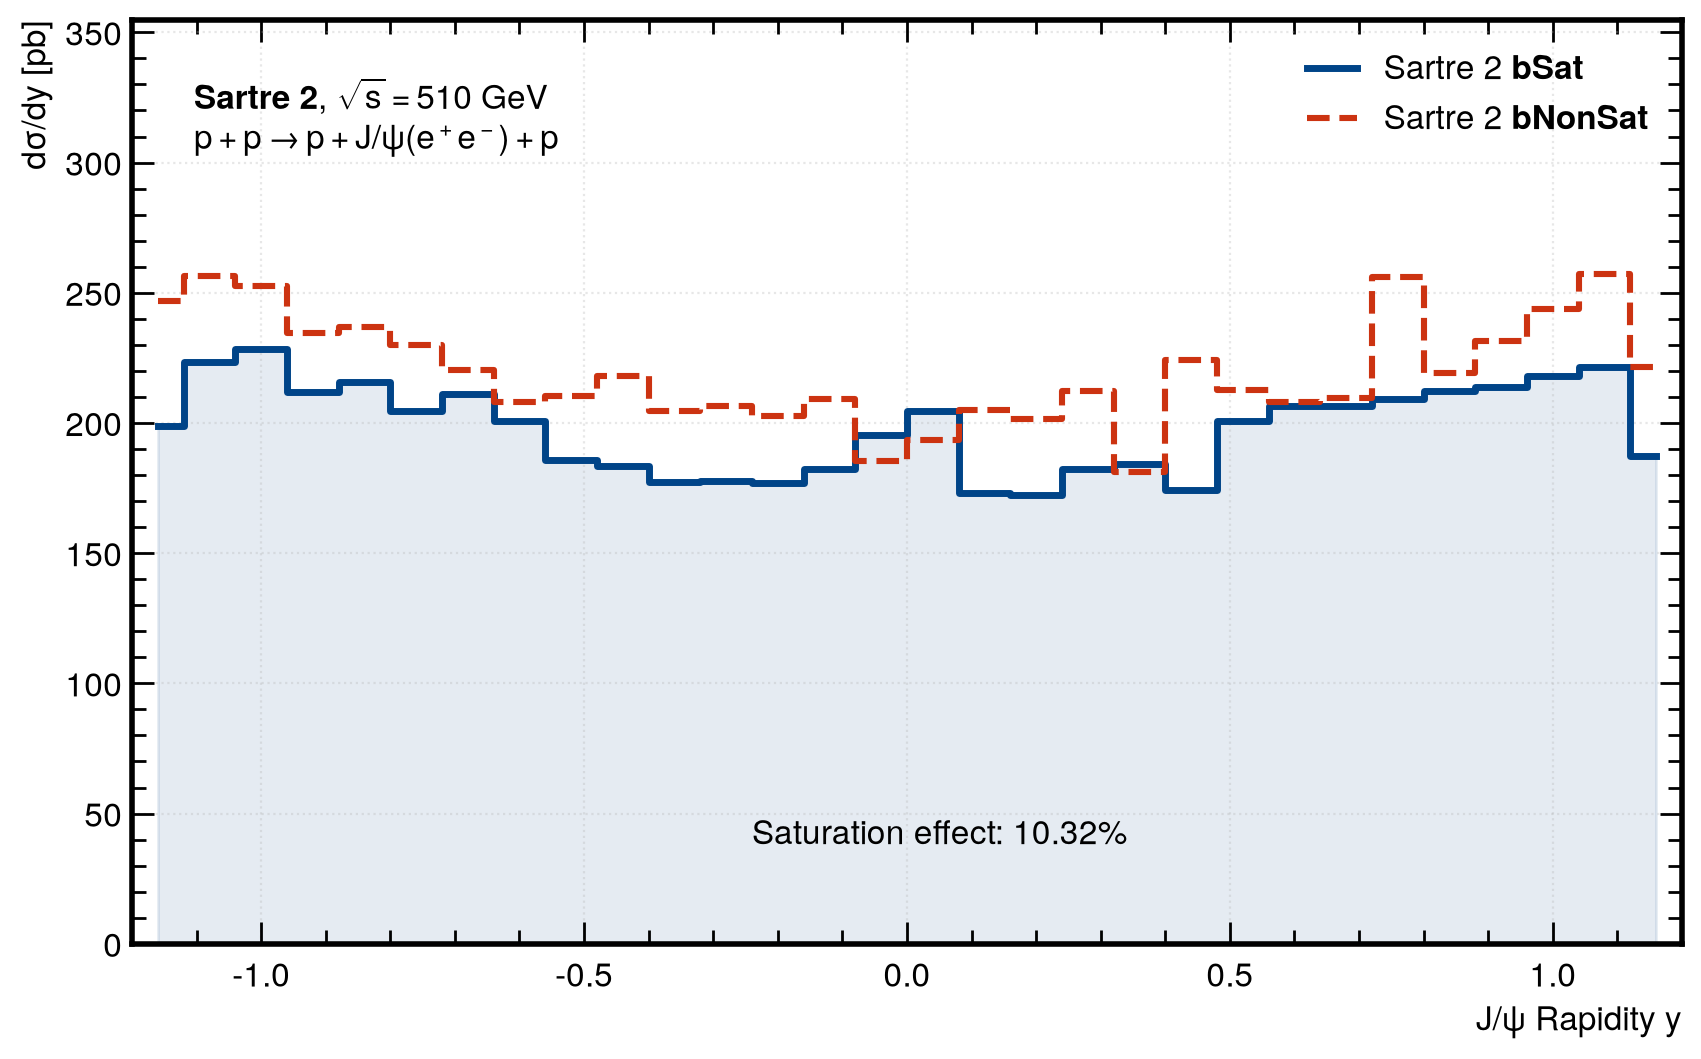

Mid-rapidity dsigma/dy(y=0):  bSat = 195.36 pb | bNonSat = 185.29 pb
Saturation effect: 10.32%


In [27]:
# -----------------------------------------------------------------------------
#  J/psi Differential Cross Section dsigma/dy vs. Rapidity y
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

bins_y = np.linspace(-1.2, 1.2, 31)
bin_w_y = bins_y[1] - bins_y[0]
centers_y = 0.5 * (bins_y[:-1] + bins_y[1:])

# Histograms
h_b_y, _ = np.histogram(data_bsat['jpsi_y'], bins=bins_y)
h_nb_y, _ = np.histogram(data_bnonsat['jpsi_y'], bins=bins_y)

ds_dy_b = (h_b_y / N_gen_b / bin_w_y) * sigma_ee_bsat_pb
ds_dy_nb = (h_nb_y / N_gen_nb / bin_w_y) * sigma_ee_bnonsat_pb

# Plot only 2 clean curves (no redundant coherent curve)
ax.step(centers_y, ds_dy_b, where='mid', color='#004488', lw=2.5,
        label=r'Sartre 2 $\mathbf{bSat}$')
ax.step(centers_y, ds_dy_nb, where='mid', color='#CC3311', lw=2.2, ls='--',
        label=r'Sartre 2 $\mathbf{bNonSat}$')
ax.fill_between(centers_y, 0, ds_dy_b, step='mid', color='#004488', alpha=0.10)

ax.set_xlabel(r'$J/\psi$ Rapidity $y$')
ax.set_ylabel(r'$d\sigma / dy$ [pb]')
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(0, max(np.max(ds_dy_b), np.max(ds_dy_nb)) * 1.38)
ax.grid(True, alpha=0.3)

# Borderless 2-line text at top-left
ax.text(0.04, 0.94, r'$\mathbf{Sartre\ 2}$, $\sqrt{s} = 510\text{ GeV}$' + '\n' +
        r'$p + p \rightarrow p + J/\psi(e^+e^-) + p$',
        transform=ax.transAxes, fontsize=12, va='top')

ax.text(0.4, 0.1, r'Saturation effect: {:.2f}%'.format((1.0 - sigma_tot_bsat_nb / sigma_tot_bnonsat_nb) * 100),
        transform=ax.transAxes, fontsize=12, va='bottom')

ax.tick_params(axis='both', which='major', length = 8, width = 1)
ax.tick_params(axis='both', which='minor', length = 5, width = 1)

# Clean legend at top-right
ax.legend(loc='upper right', frameon=False, fontsize=12)

plt.savefig(FIG_DIR / "fig_01_jpsi_dsigma_dy.pdf", bbox_inches='tight')
plt.show()

mid_idx = len(bins_y) // 2 - 1
print(f"Mid-rapidity dsigma/dy(y=0):  bSat = {ds_dy_b[mid_idx]:.2f} pb | bNonSat = {ds_dy_nb[mid_idx]:.2f} pb")
print(f"Saturation effect: {(1.0 - sigma_tot_bsat_nb / sigma_tot_bnonsat_nb)*100:.2f}%")

---

### Electron Pseudorapidity Distribution $\eta_e$ & STAR Central Acceptance Cut


To be captired by central detector, both leptons must satisfy $|\eta_{e^\pm}| < 0.9$.
Requiring *both* daughter electrons to simultaneously fall into $|\eta_e| < 0.9$ (shaded band) selects events where the parent $J/\psi$ was produced near mid-rapidity give a central acceptance fraction of $\approx 5.26\%$ in `bSat`.

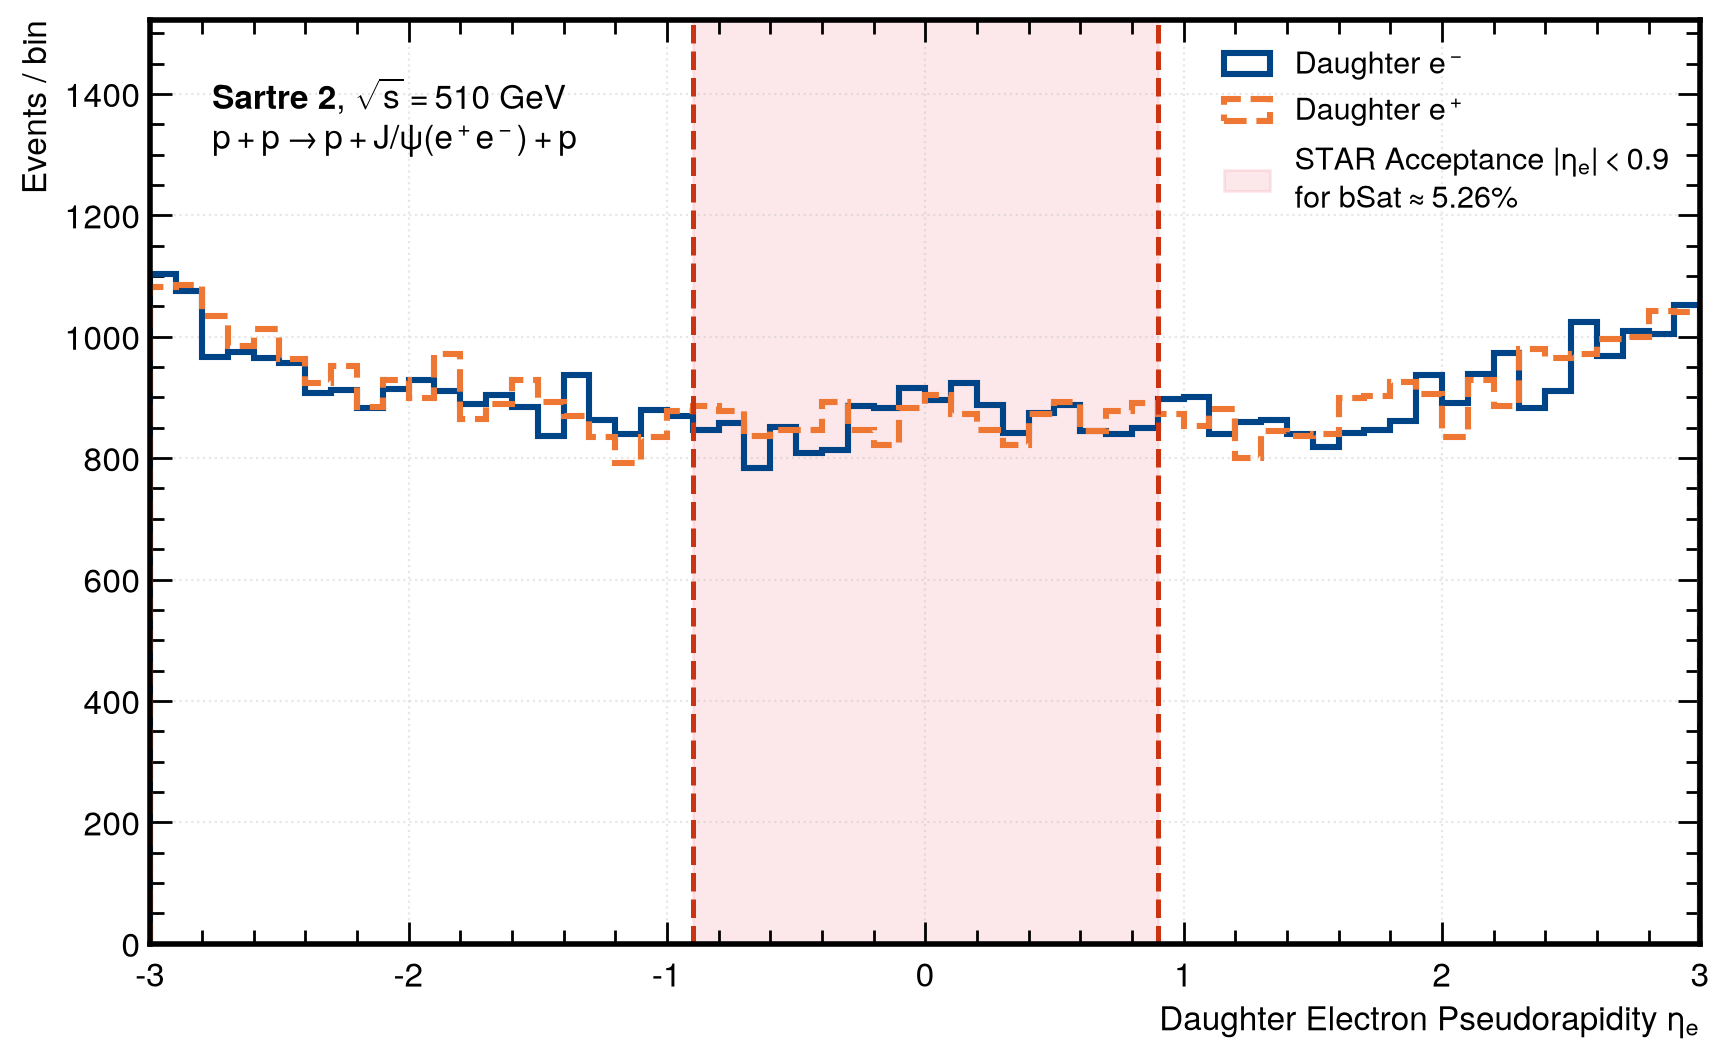

Both electrons |eta_e| < 0.9 (Cut C5): 5,259 / 99,998 (5.26%)


In [26]:
# -----------------------------------------------------------------------------
# Plot 7.2: Daughter Electron Pseudorapidity Distribution & Central Cut
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

bins_eta = np.linspace(-3.0, 3.0, 61)

c5_mask_b = (np.abs(data_bsat['em_eta']) < 0.9) & (np.abs(data_bsat['ep_eta']) < 0.9)

h_em, _ = np.histogram(data_bsat['em_eta'], bins=bins_eta)
h_ep, _ = np.histogram(data_bsat['ep_eta'], bins=bins_eta)
max_c = max(np.max(h_em), np.max(h_ep))

ax.hist(data_bsat['em_eta'], bins=bins_eta, histtype='step', lw=2.2, color='#004488',
        label=r'Daughter $e^-$')
ax.hist(data_bsat['ep_eta'], bins=bins_eta, histtype='step', lw=2.2, color='#EE7733', ls='--',
        label=r'Daughter $e^+$')

# STAR Central Fiducial Acceptance
ax.axvspan(-0.9, 0.9, color='#EE6677', alpha=0.15,
          label=r'STAR Acceptance $|\eta_e| < 0.9$' + '\n' + r'for bSat$\approx 5.26\%$')
ax.axvline(-0.9, color='#CC3311', lw=1.8, ls='--')
ax.axvline(0.9, color='#CC3311', lw=1.8, ls='--')

ax.set_xlabel(r'Daughter Electron Pseudorapidity $\eta_e$')
ax.set_ylabel(r'Events / bin')
ax.set_xlim(-3.0, 3.0)
ax.set_ylim(0, max_c * 1.38)
ax.grid(True, alpha=0.3)

# Borderless 2-line text at top-left
ax.text(0.04, 0.94, r'$\mathbf{Sartre\ 2}$, $\sqrt{s} = 510\text{ GeV}$' + '\n' +
        r'$p + p \rightarrow p + J/\psi(e^+e^-) + p$',
        transform=ax.transAxes, fontsize=12, va='top')

ax.tick_params(axis='both', which='major', length = 8, width = 1)
ax.tick_params(axis='both', which='minor', length = 5, width = 1)

# Clean legend at top-right
ax.legend(loc='upper right', frameon=False, fontsize=11)

plt.savefig(FIG_DIR / "fig_02_electron_pseudorapidity_acceptance.pdf", bbox_inches='tight')
plt.show()

frac_c5_b = 100.0 * np.sum(c5_mask_b) / N_gen_b
print(f"Both electrons |eta_e| < 0.9 (Cut C5): {np.sum(c5_mask_b):,} / {N_gen_b:,} ({frac_c5_b:.2f}%)")

---

### Dielectron Invariant Mass Spectrum $M(e^+e^-)$

Just a reality check if we get physically reasonable $J/\psi$ mass. 
We recover the expected $J/\psi$ peak at $M_{J/\psi} \approx 3.0969\text{ GeV}/c^2$ with a width of $\Gamma_{\text{FWHM}} \approx 92.4\text{ keV}$.

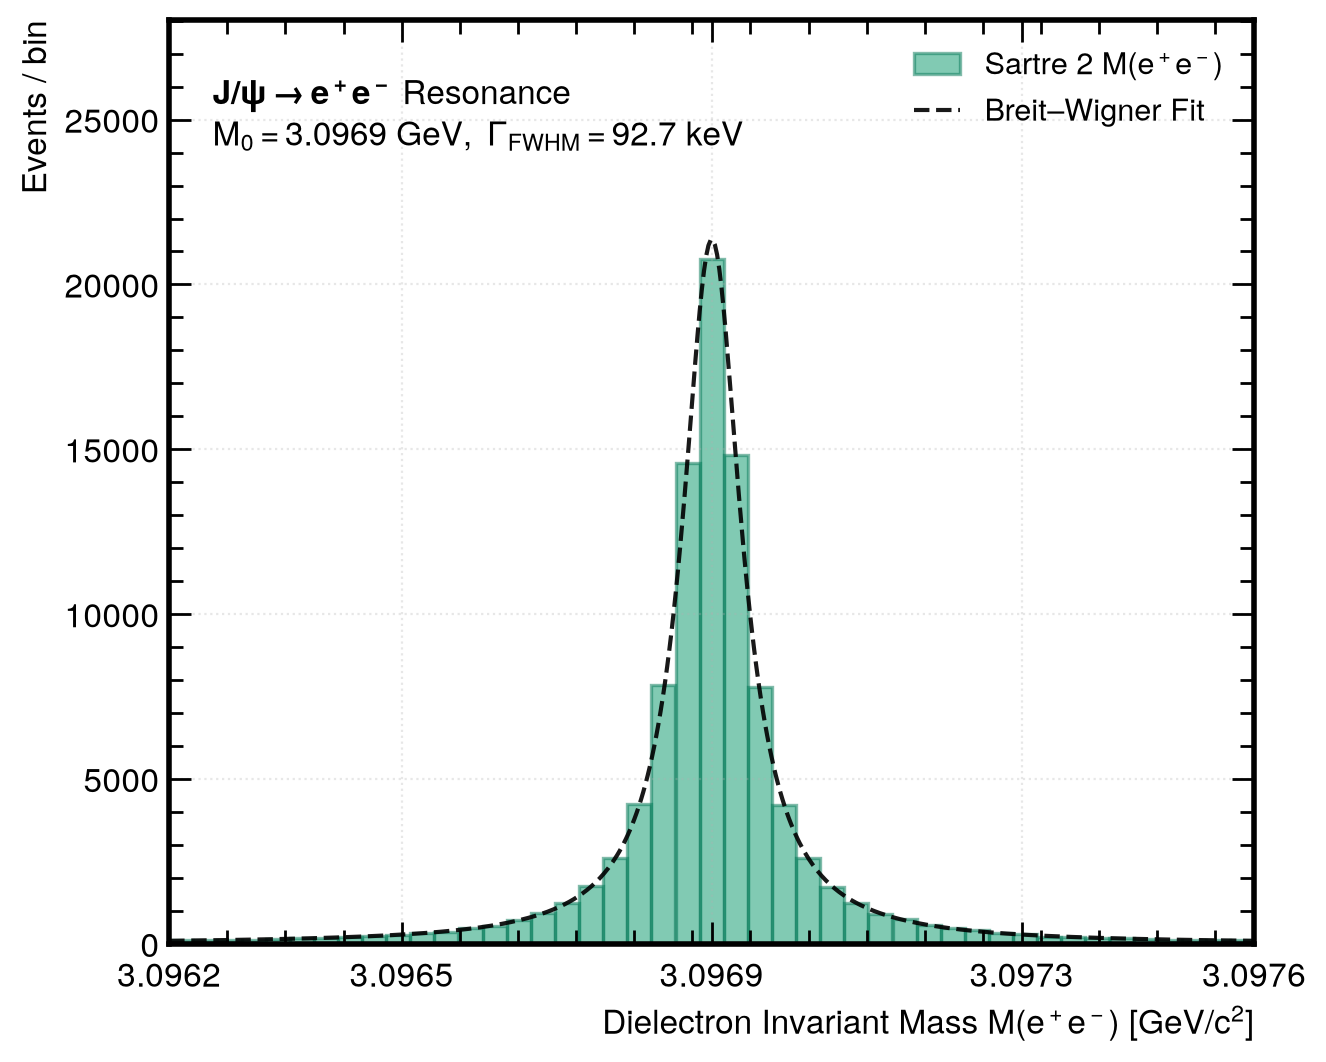

Breit-Wigner Fit $M_0$ = 3.096900 GeV/c^2, Gamma = 92.7 keV


In [25]:
# -----------------------------------------------------------------------------
# Dielectron Invariant Mass Spectrum M(e+e-)
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 6))

pair_m = data_bsat['pair_m']

# Fit Cauchy distribution to extract true Breit-Wigner peak position and FWHM
loc_m, scale_m = stats.cauchy.fit(pair_m)
fwhm_m = 2.0 * scale_m

# Zoom window centered on resonance peak [3.0962, 3.0976] GeV/c^2 (45 bins)
m_min, m_max = 3.0962, 3.0976
bins_m = np.linspace(m_min, m_max, 46)
bw_m = bins_m[1] - bins_m[0]

in_win = (pair_m >= m_min) & (pair_m <= m_max)
h_m, _, _ = ax.hist(pair_m[in_win], bins=bins_m, color='#059669', alpha=0.5,
                    edgecolor='#047857', lw=1.2, label=r'Sartre 2 $M(e^+e^-)$')
max_c = np.max(h_m)

# Overlay theoretical Breit-Wigner curve
m_eval = np.linspace(m_min, m_max, 500)
bw_pdf = stats.cauchy.pdf(m_eval, loc=loc_m, scale=scale_m)
bw_curve = bw_pdf * len(pair_m) * bw_m
ax.plot(m_eval, bw_curve, color="#000000",linestyle='--', lw=1.5, label=r'Breit–Wigner Fit', alpha=0.9)

ax.set_xlabel(r'Dielectron Invariant Mass $M(e^+e^-)$ [$\text{GeV}/c^2$]')
ax.set_ylabel(r'Events / bin')
ax.set_xlim(m_min, m_max)
ax.set_ylim(0, max_c * 1.35)
ax.set_xticks([3.0962, 3.0965, 3.0969, 3.0973, 3.0976])
ax.xaxis.set_major_formatter(ticker.FormatStrFormatter('%.4f'))
ax.grid(True, alpha=0.3)

# Borderless text with pole mass and FWHM
ax.text(0.04, 0.94, r'$\mathbf{J/\psi \rightarrow e^+e^-}$ Resonance' + '\n' +
        f'$M_0 = {loc_m:.4f}\\text{{ GeV}},\\ \\Gamma_{{\\mathrm{{FWHM}}}} = {fwhm_m*1e6:.1f}\\text{{ keV}}$',
        transform=ax.transAxes, fontsize=12, va='top')

ax.tick_params(axis='both', which='major', length = 8, width = 1)
ax.tick_params(axis='both', which='minor', length = 5, width = 1)

# Clean 2-entry legend at top-right
ax.legend(loc='upper right', frameon=False, fontsize=11)

plt.savefig(FIG_DIR / "fig_03_dielectron_invariant_mass.pdf", bbox_inches='tight')
plt.show()

print(f"Breit-Wigner Fit $M_0$ = {loc_m:.6f} GeV/c^2, Gamma = {fwhm_m*1e6:.1f} keV")

---

### Daughter Electron and Positron Transverse Momentum $p_T^e$

**Physical Motivation:**  
Because the $J/\psi$ two-body decay produces a **Jacobian peak** just below the kinematic limit $p_T^{e, \max} \approx M_{J/\psi}/2 = 1.55\text{ GeV}/c$. Again, expected, plotted just for sanity check.

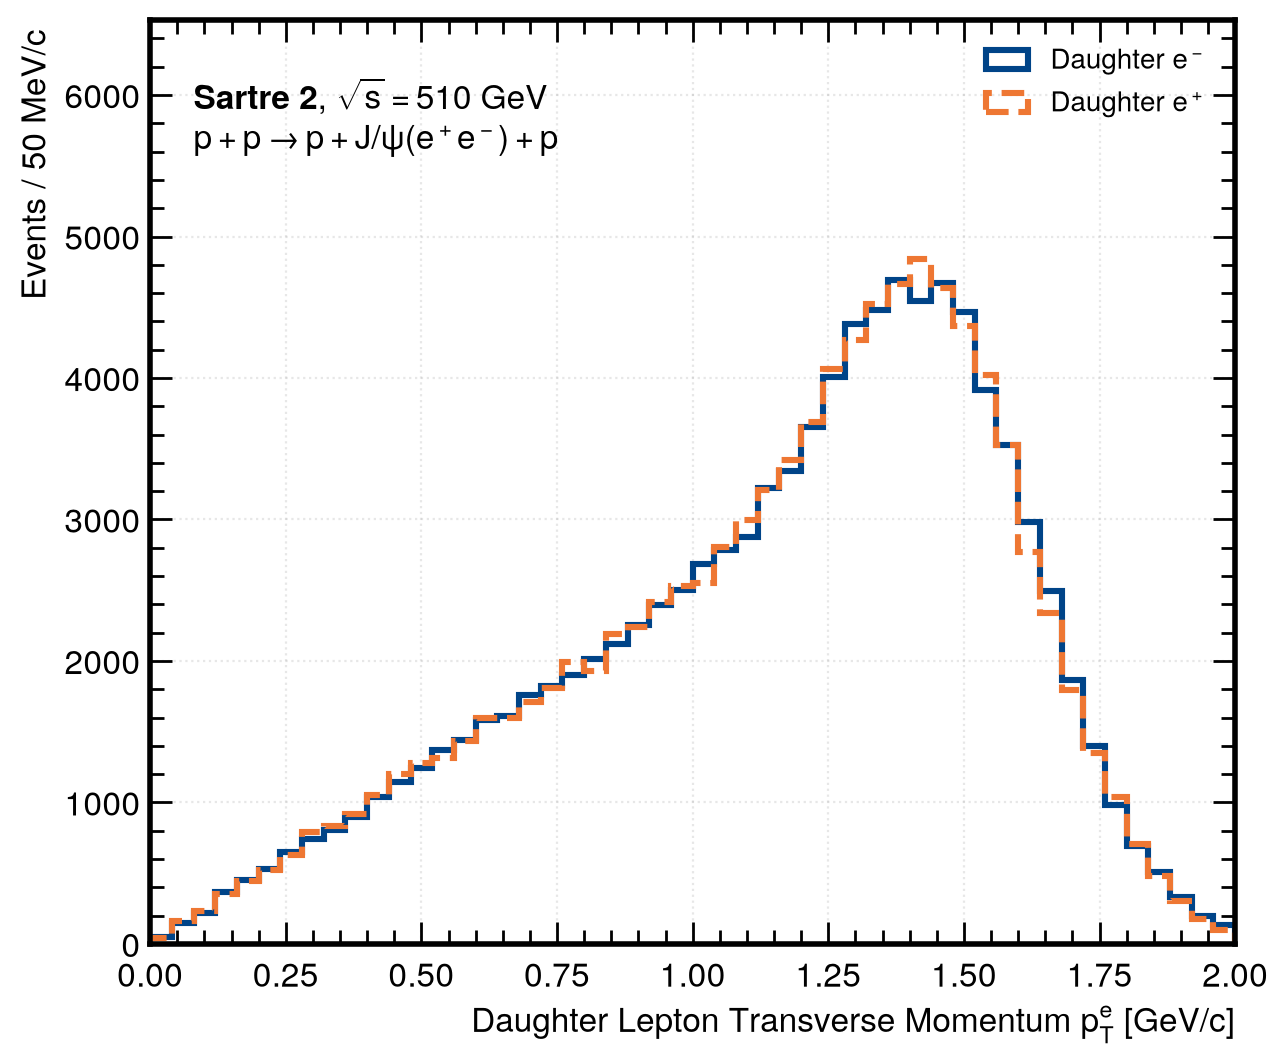

Daughter electron kinematics: Mean pT = 1.165 GeV/c, Median pT = 1.244 GeV/c


In [24]:
# -----------------------------------------------------------------------------
# Daughter Electron and Positron Transverse Momentum pT^e
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 6))

bins_ept = np.linspace(0.0, 2.0, 51)
h_em, _ = np.histogram(data_bsat['em_pt'], bins=bins_ept)
h_ep, _ = np.histogram(data_bsat['ep_pt'], bins=bins_ept)
max_ept = max(np.max(h_em), np.max(h_ep))

ax.hist(data_bsat['em_pt'], bins=bins_ept, histtype='step', lw=2.2, color='#004488',
        label=r'Daughter $e^-$')
ax.hist(data_bsat['ep_pt'], bins=bins_ept, histtype='step', lw=2.2, color='#EE7733', ls='--',
        label=r'Daughter $e^+$')

#ax.axvline(1.548, color='#CC3311', lw=1.8, ls='-', label=r'Jacobian Edge $1.55\text{ GeV}/c$')
#ax.axvline(0.3, color='#33BBEE', lw=1.8, ls='-.', label=r'BEMC Threshold $0.3\text{ GeV}/c$')

ax.set_xlabel(r'Daughter Lepton Transverse Momentum $p_T^e$ [$\text{GeV}/c$]')
ax.set_ylabel(r'Events / $50\text{ MeV}/c$ ')
ax.set_xlim(0.0, 2.0)
ax.set_ylim(0, max_ept * 1.35)
ax.grid(True, alpha=0.3)

# Borderless 2-line text at top-left
ax.text(0.04, 0.94, r'$\mathbf{Sartre\ 2}$, $\sqrt{s} = 510\text{ GeV}$' + '\n' +
        r'$p + p \rightarrow p + J/\psi(e^+e^-) + p$',
        transform=ax.transAxes, fontsize=12, va='top')

ax.tick_params(axis='both', which='major', length = 8, width = 1)
ax.tick_params(axis='both', which='minor', length = 5, width = 1)

# Clean legend at top-right
ax.legend(loc='upper right', frameon=False, fontsize=10)

plt.savefig(FIG_DIR / "fig_04_electron_pt_distribution.pdf", bbox_inches='tight')
plt.show()

print(f"Daughter electron kinematics: Mean pT = {np.mean(data_bsat['em_pt']):.3f} GeV/c, Median pT = {np.median(data_bsat['em_pt']):.3f} GeV/c")

---

### $J/\psi$ Transverse Momentum Differential Cross Section $d\sigma/dp_T$

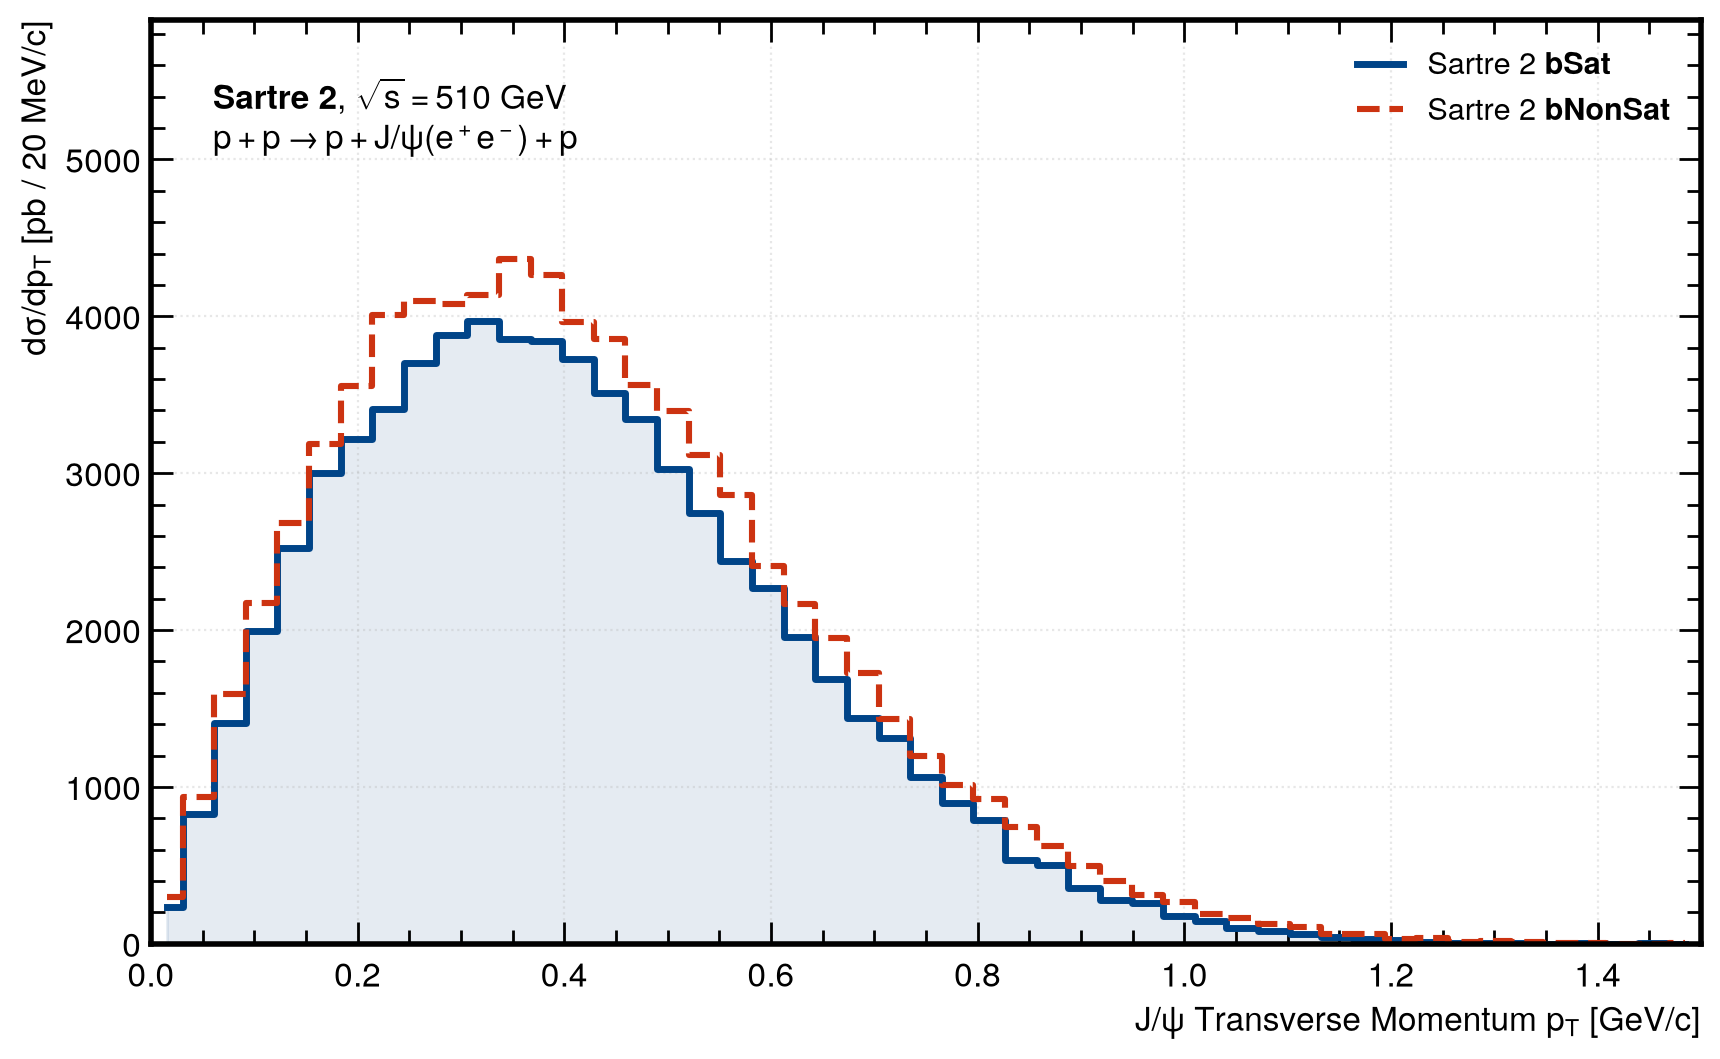

In [23]:
# -----------------------------------------------------------------------------
# J/psi Transverse Momentum Differential Cross Section dsigma/dpT
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

bins_pt = np.linspace(0.0, 1.5, 50)
bw_pt = bins_pt[1] - bins_pt[0]
cpt = 0.5 * (bins_pt[:-1] + bins_pt[1:])

hb_pt, _ = np.histogram(data_bsat['jpsi_pt'], bins=bins_pt)
hnb_pt, _ = np.histogram(data_bnonsat['jpsi_pt'], bins=bins_pt)

ds_pt_b = (hb_pt / N_gen_b / bw_pt) * sigma_ee_bsat_pb
ds_pt_nb = (hnb_pt / N_gen_nb / bw_pt) * sigma_ee_bnonsat_pb
max_pt = max(np.max(ds_pt_b), np.max(ds_pt_nb))

ax.step(cpt, ds_pt_b, where='mid', color='#004488', lw=2.5, label=r'Sartre 2 $\mathbf{bSat}$')
ax.step(cpt, ds_pt_nb, where='mid', color='#CC3311', lw=2.2, ls='--', label=r'Sartre 2 $\mathbf{bNonSat}$')
ax.fill_between(cpt, 0, ds_pt_b, step='mid', color='#004488', alpha=0.10)

ax.set_xlabel(r'$J/\psi$ Transverse Momentum $p_T$ [$\text{GeV}/c$]')
ax.set_ylabel(r'$d\sigma / dp_T$ [pb / $20\text{ MeV}/c$]')
ax.set_xlim(0.0, 1.5)
ax.set_ylim(0, max_pt * 1.35)
ax.grid(True, alpha=0.3)

# Borderless 2-line text at top-left
ax.text(0.04, 0.94, r'$\mathbf{Sartre\ 2}$, $\sqrt{s} = 510\text{ GeV}$' + '\n' +
        r'$p + p \rightarrow p + J/\psi(e^+e^-) + p$',
        transform=ax.transAxes, fontsize=12, va='top')

ax.tick_params(axis='both', which='major', length = 8, width = 1)
ax.tick_params(axis='both', which='minor', length = 5, width = 1)

# Clean legend at top-right
ax.legend(loc='upper right', frameon=False, fontsize=11)

plt.savefig(FIG_DIR / "fig_05_jpsi_dsigma_dpt.pdf", bbox_inches='tight')
plt.show()

---

### Target (Pomeron) Proton $(p_x, p_y)$ Distribution with STAR Roman Pot Acceptance

Forward scattered protons are detected by silicon strip detectors inside movable Roman Pot vessels at $z = \pm 15.8\text{ m}$ and $\pm 17.6\text{ m}$. Protons are accepted only inside the fiducial boundary (**Cut F2** from Michals thesis):

$$
(p_x + 0.6\text{ GeV}/c)^2 + p_y^2 < 1.25\text{ GeV}^2/c^2, \qquad 0.4\text{ GeV}/c < |p_y| < 0.8\text{ GeV}/c, \qquad p_x > -0.27\text{ GeV}/c
$$

Protons with $|p_y| < 0.4\text{ GeV}/c$ stay inside the beam pipe, while the red contours outline the Upper ($p_y > 0$) and Lower ($p_y < 0$) Roman Pot fiducial acceptance windows.


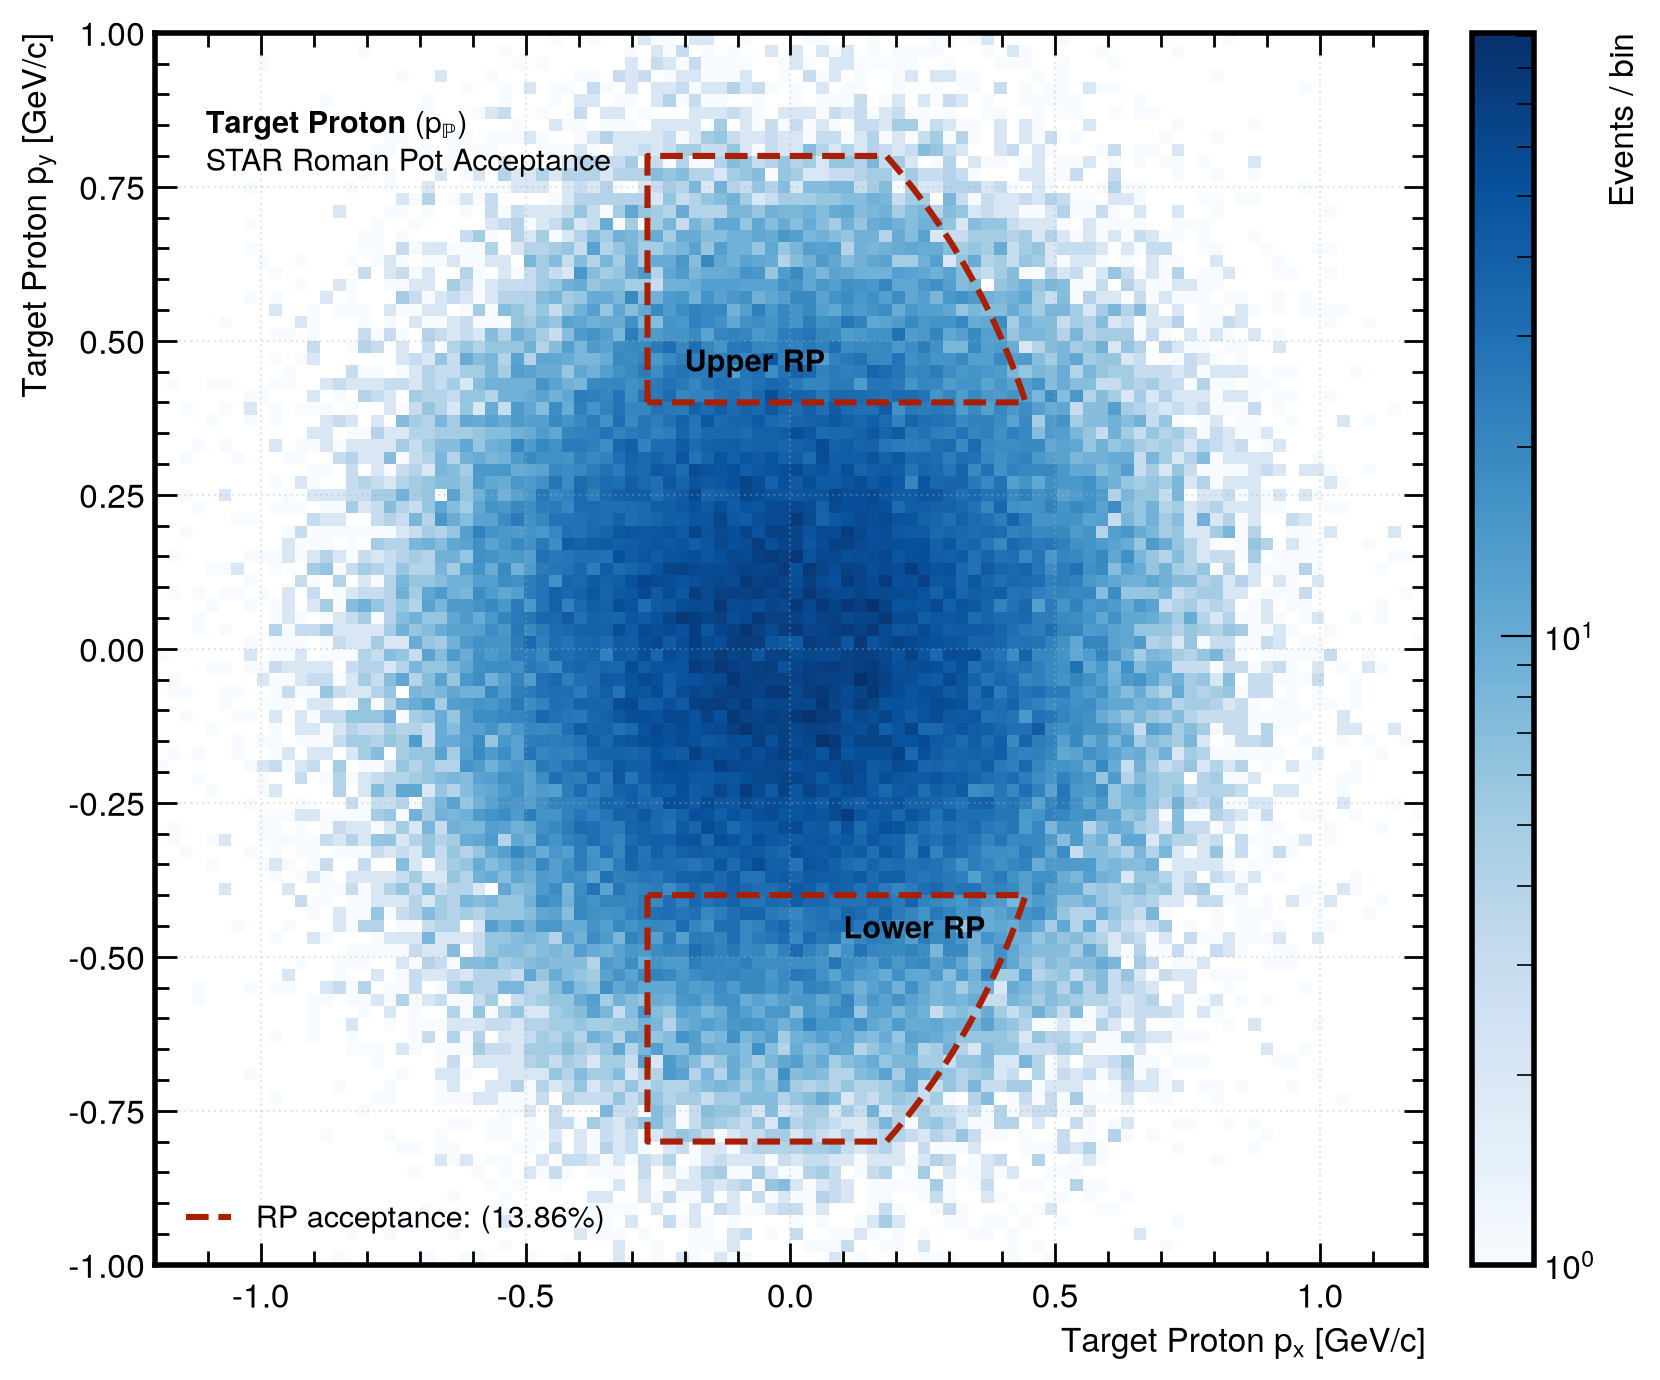

Target proton Roman Pot fiducial acceptance: 13,855 / 99,998 (13.86%)


In [22]:
# -----------------------------------------------------------------------------
# Target Proton 2D (px, py) with STAR Roman Pot Acceptance
# -----------------------------------------------------------------------------
def get_rp_polygons():
    py_arc_up = np.linspace(0.8, 0.4, 40)
    px_arc_up = np.sqrt(1.25 - py_arc_up**2) - 0.6
    poly_up = np.vstack([
        [-0.27, 0.4],
        [-0.27, 0.8],
        [np.sqrt(1.25 - 0.8**2) - 0.6, 0.8],
        np.column_stack([px_arc_up, py_arc_up]),
        [np.sqrt(1.25 - 0.4**2) - 0.6, 0.4],
        [-0.27, 0.4]
    ])
    py_arc_down = np.linspace(-0.8, -0.4, 40)
    px_arc_down = np.sqrt(1.25 - py_arc_down**2) - 0.6
    poly_down = np.vstack([
        [-0.27, -0.4],
        [-0.27, -0.8],
        [np.sqrt(1.25 - 0.8**2) - 0.6, -0.8],
        np.column_stack([px_arc_down, py_arc_down]),
        [np.sqrt(1.25 - 0.4**2) - 0.6, -0.4],
        [-0.27, -0.4]
    ])
    return poly_up, poly_down

fig, ax = plt.subplots(figsize=(10, 8))

h2, xedges, yedges, im = ax.hist2d(
    data_bsat['p_pom_px'], data_bsat['p_pom_py'], bins=100,
    range=[[-1.2, 1.2], [-1.0, 1.0]], norm=LogNorm(), cmap='Blues', cmin=1
)
cbar = fig.colorbar(im, ax=ax, pad=0.03)
cbar.set_label(r'Events / bin')

poly_up, poly_down = get_rp_polygons()
ax.plot(poly_up[:, 0], poly_up[:, 1], color="#AA1F00", lw=2.2, ls='--', label=f'RP acceptance: ({100.0*np.sum(cond_rp)/N_gen_b:.2f}%)')
ax.plot(poly_down[:, 0], poly_down[:, 1], color="#AA1F00", lw=2.2, ls='--')

ax.text(-0.2, 0.45, 'Upper RP', color="#000000", fontsize=11, fontweight='bold')
ax.text(0.1, -0.47, 'Lower RP', color="#000000", fontsize=11, fontweight='bold')

# Clean borderless label in empty top-left quadrant
ax.text(0.04, 0.94, r'$\mathbf{Target\ Proton}\ (p_{\mathbb{P}})$' + '\n' +
        r'STAR Roman Pot Acceptance',
        transform=ax.transAxes, fontsize=11, va='top', color='black')

ax.set_xlabel(r'Target Proton $p_x$ [$\text{GeV}/c$]')
ax.set_ylabel(r'Target Proton $p_y$ [$\text{GeV}/c$]')
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.0, 1.0)
ax.grid(True, alpha=0.3)
ax.legend(loc='lower left', frameon=False, fontsize=11)

ax.tick_params(axis='both', which='major', length = 8, width = 1)
ax.tick_params(axis='both', which='minor', length = 5, width = 1)

plt.savefig(FIG_DIR / "fig_06_proton_pom_2d_px_py_rp_acceptance.pdf", bbox_inches='tight')
plt.show()

cond_rp = ((data_bsat['p_pom_px'] + 0.6)**2 + data_bsat['p_pom_py']**2 < 1.25) & \
          (np.abs(data_bsat['p_pom_py']) > 0.4) & (np.abs(data_bsat['p_pom_py']) < 0.8) & \
          (data_bsat['p_pom_px'] > -0.27)
print(f"Target proton Roman Pot fiducial acceptance: {np.sum(cond_rp):,} / {N_gen_b:,} ({100.0*np.sum(cond_rp)/N_gen_b:.2f}%)")

---

### Decomposed 1D $p_x$ and $p_y$ Distributions of the Target Proton with Roman Pot Acceptance

This figure decomposes the 2D $(p_x, p_y)$ distribution into two side-by-side 1D projections to show how the forward Roman Pot silicon detectors slice through the scattered proton phase space:
- **Left panel ($p_x$):** The DX dipole magnet creates an asymmetric acceptance window with a lower cutoff at $p_x = -0.27\text{ GeV}/c$ and an arc boundary at $p_x = +0.444\text{ GeV}/c$.
- **Right panel ($p_y$):** The beam pipe requires a vertical dead zone $|p_y| < 0.4\text{ GeV}/c$, while the vessel dimensions cap detection at $|p_y| = 0.8\text{ GeV}/c$, splitting acceptance into Upper ($p_y \in [0.4, 0.8]\text{ GeV}/c$) and Lower ($p_y \in [-0.8, -0.4]\text{ GeV}/c$) branches.

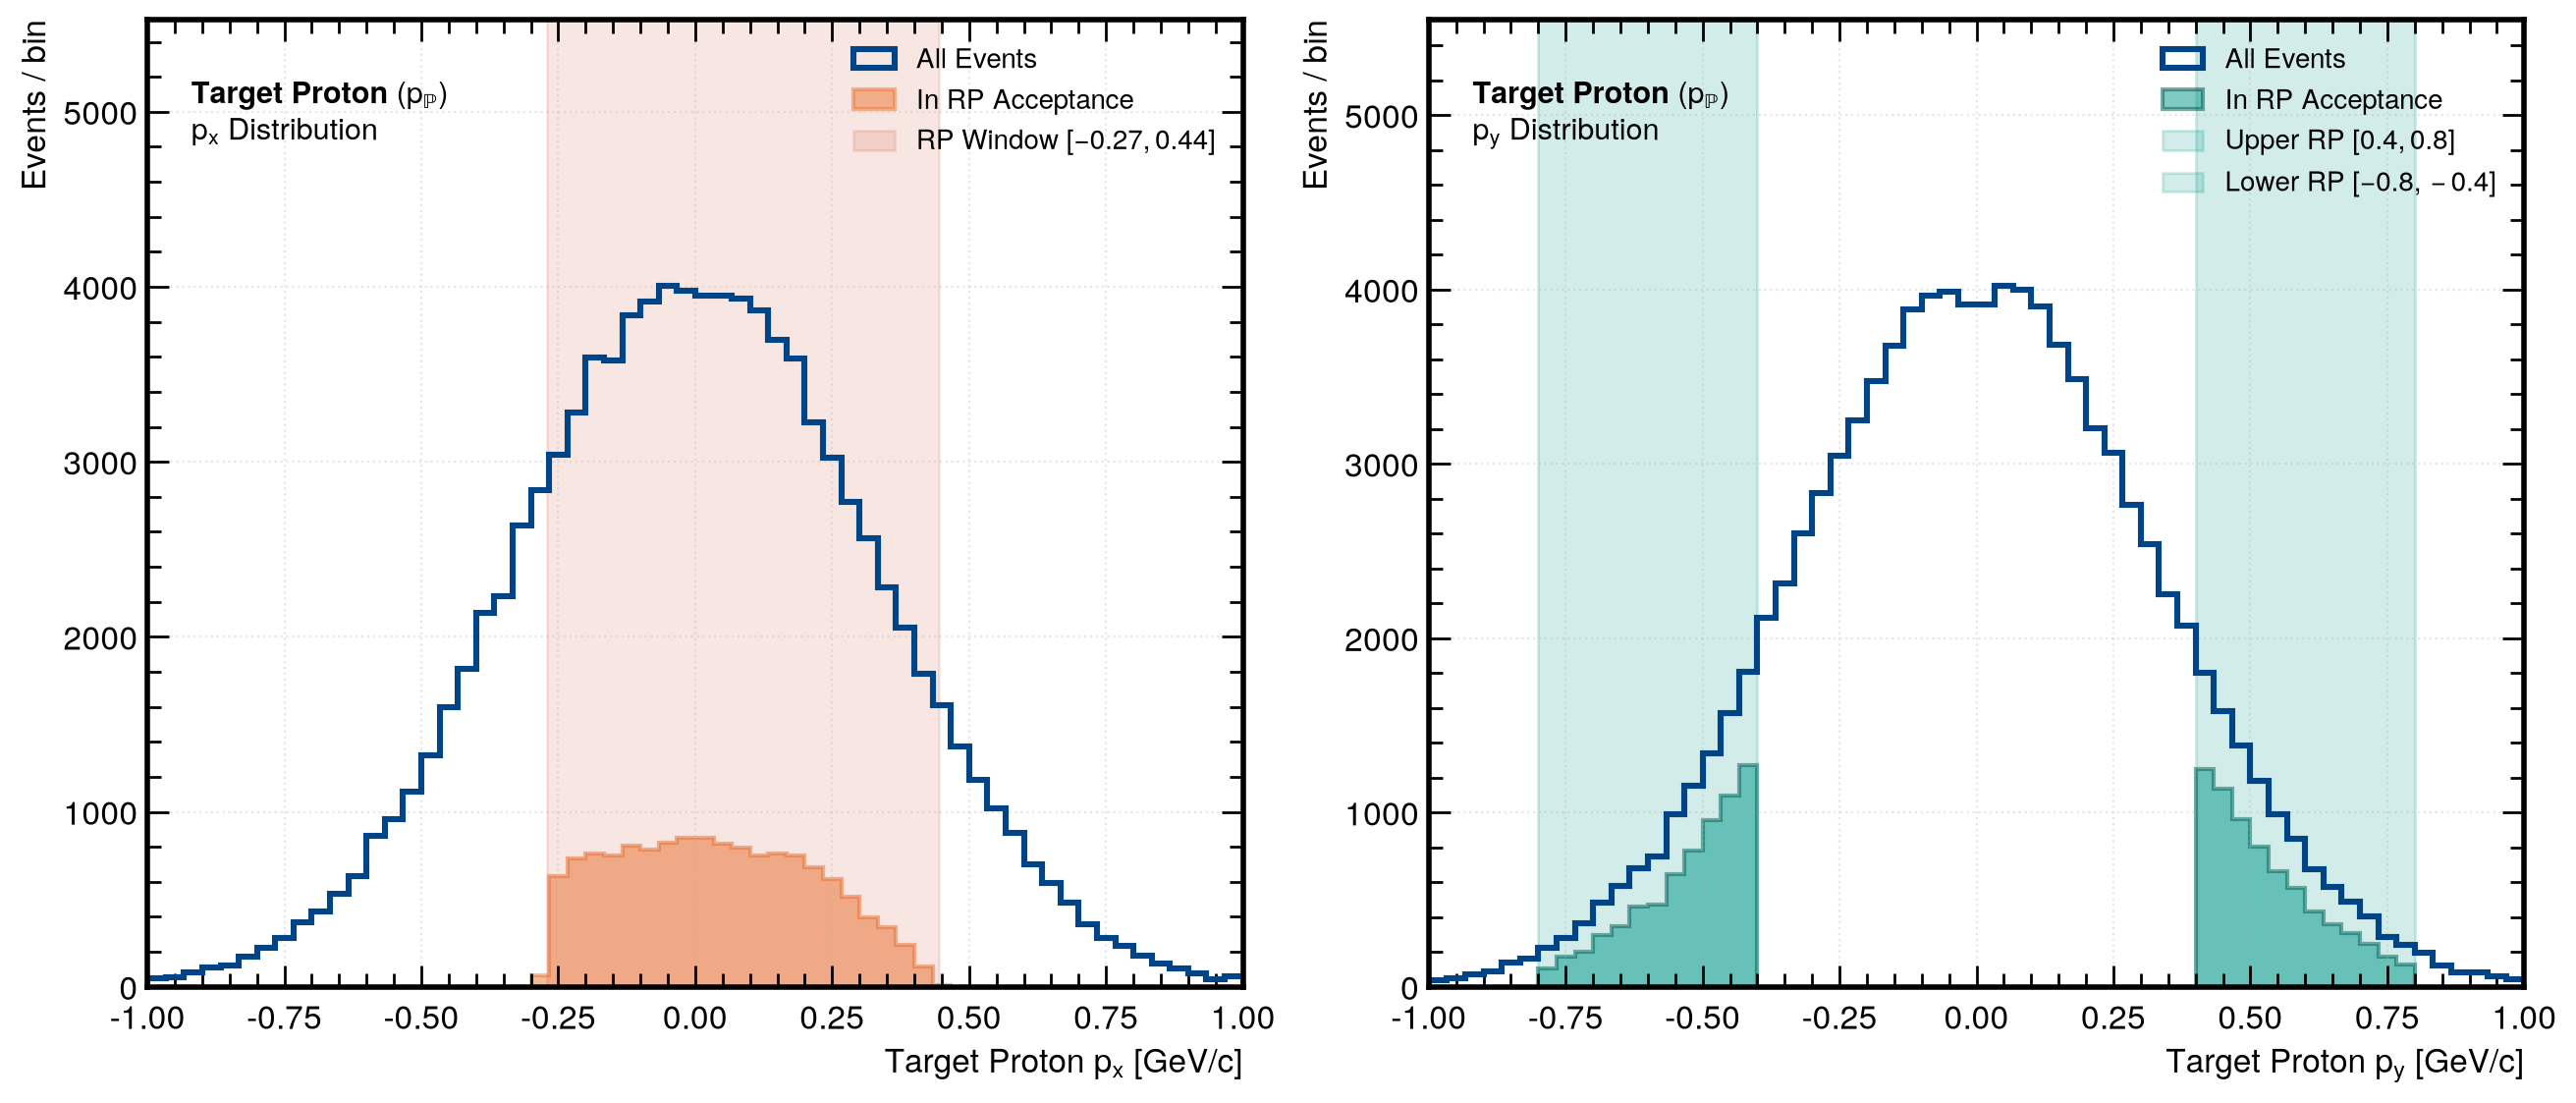

In [ ]:
# -----------------------------------------------------------------------------
# Decomposed 1D px and py Distributions of Target Proton
# -----------------------------------------------------------------------------
fig, (ax_px, ax_py) = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)

bins_p1d = np.linspace(-1.0, 1.0, 61)

cond_rp_b = ((data_bsat['p_pom_px'] + 0.6)**2 + data_bsat['p_pom_py']**2 < 1.25) & \
            (np.abs(data_bsat['p_pom_py']) > 0.4) & (np.abs(data_bsat['p_pom_py']) < 0.8) & \
            (data_bsat['p_pom_px'] > -0.27)

# Left panel: px projection
h_px_all, _ = np.histogram(data_bsat['p_pom_px'], bins=bins_p1d)
max_px = np.max(h_px_all)
ax_px.hist(data_bsat['p_pom_px'], bins=bins_p1d, histtype='step', lw=2.2, color='#004488',
           label='All Events')
ax_px.hist(data_bsat['p_pom_px'][cond_rp_b], bins=bins_p1d, histtype='stepfilled',
           color='#EE7733', alpha=0.5, edgecolor='#EE7733', lw=1.5,
           label='In RP Acceptance')
ax_px.axvspan(-0.27, 0.444, color='#CC3311', alpha=0.12, label=r'RP Window $[-0.27, 0.44]$')

ax_px.set_xlabel(r'Target Proton $p_x$ [$\text{GeV}/c$]')
ax_px.set_ylabel(r'Events / bin')
ax_px.set_xlim(-1.0, 1.0)
ax_px.set_ylim(0, max_px * 1.38)
ax_px.grid(True, alpha=0.3)
ax_px.legend(loc='upper right', frameon=False, fontsize=10)
ax_px.text(0.04, 0.94, r'$\mathbf{Target\ Proton}\ (p_{\mathbb{P}})$' + '\n' + r'$p_x\ \text{Distribution}$',
           transform=ax_px.transAxes, fontsize=11, va='top')

# Right panel: py projection
h_py_all, _ = np.histogram(data_bsat['p_pom_py'], bins=bins_p1d)
max_py = np.max(h_py_all)
ax_py.hist(data_bsat['p_pom_py'], bins=bins_p1d, histtype='step', lw=2.2, color='#004488',
           label='All Events')
ax_py.hist(data_bsat['p_pom_py'][cond_rp_b], bins=bins_p1d, histtype='stepfilled',
           color='#009988', alpha=0.5, edgecolor="#005249", lw=1.5,
           label='In RP Acceptance')
ax_py.axvspan(0.4, 0.8, color='#009988', alpha=0.18, label=r'Upper RP $[0.4, 0.8]$')
ax_py.axvspan(-0.8, -0.4, color='#009988', alpha=0.18, label=r'Lower RP $[-0.8, -0.4]$')

ax_py.set_xlabel(r'Target Proton $p_y$ [$\text{GeV}/c$]')
ax_py.set_ylabel(r'Events / bin')
ax_py.set_xlim(-1.0, 1.0)
ax_py.set_ylim(0, max_py * 1.38)
ax_py.grid(True, alpha=0.3)
ax_py.legend(loc='upper right', frameon=False, fontsize=10)
ax_py.text(0.04, 0.94, r'$\mathbf{Target\ Proton}\ (p_{\mathbb{P}})$' + '\n' + r'$p_y\ \text{Distribution}$',
           transform=ax_py.transAxes, fontsize=11, va='top')

ax_py.tick_params(axis='both', which='major', length = 8, width = 1)
ax_py.tick_params(axis='both', which='minor', length = 5, width = 1)
ax_px.tick_params(axis='both', which='major', length = 8, width = 1)
ax_px.tick_params(axis='both', which='minor', length = 5, width = 1)

plt.savefig(FIG_DIR / "fig_07_proton_pom_1d_px_py_decomposed.pdf", bbox_inches='tight')
plt.show()

---

### 2D $(p_x, p_y)$ Distribution with Marginal 1D $p_x$ and $p_y$ Projections

This figure puts the 2D phase-space distribution and its marginal 1D horizontal ($p_x$) and vertical ($p_y$) projections into a single layout using `matplotlib.gridspec.GridSpec`.

The central 2D density plot displays the proton momentum distribution overlaid with the red Roman Pot acceptance polygons. The shared-axis marginal panels highlight how the acceptance cuts slice through the distributions.

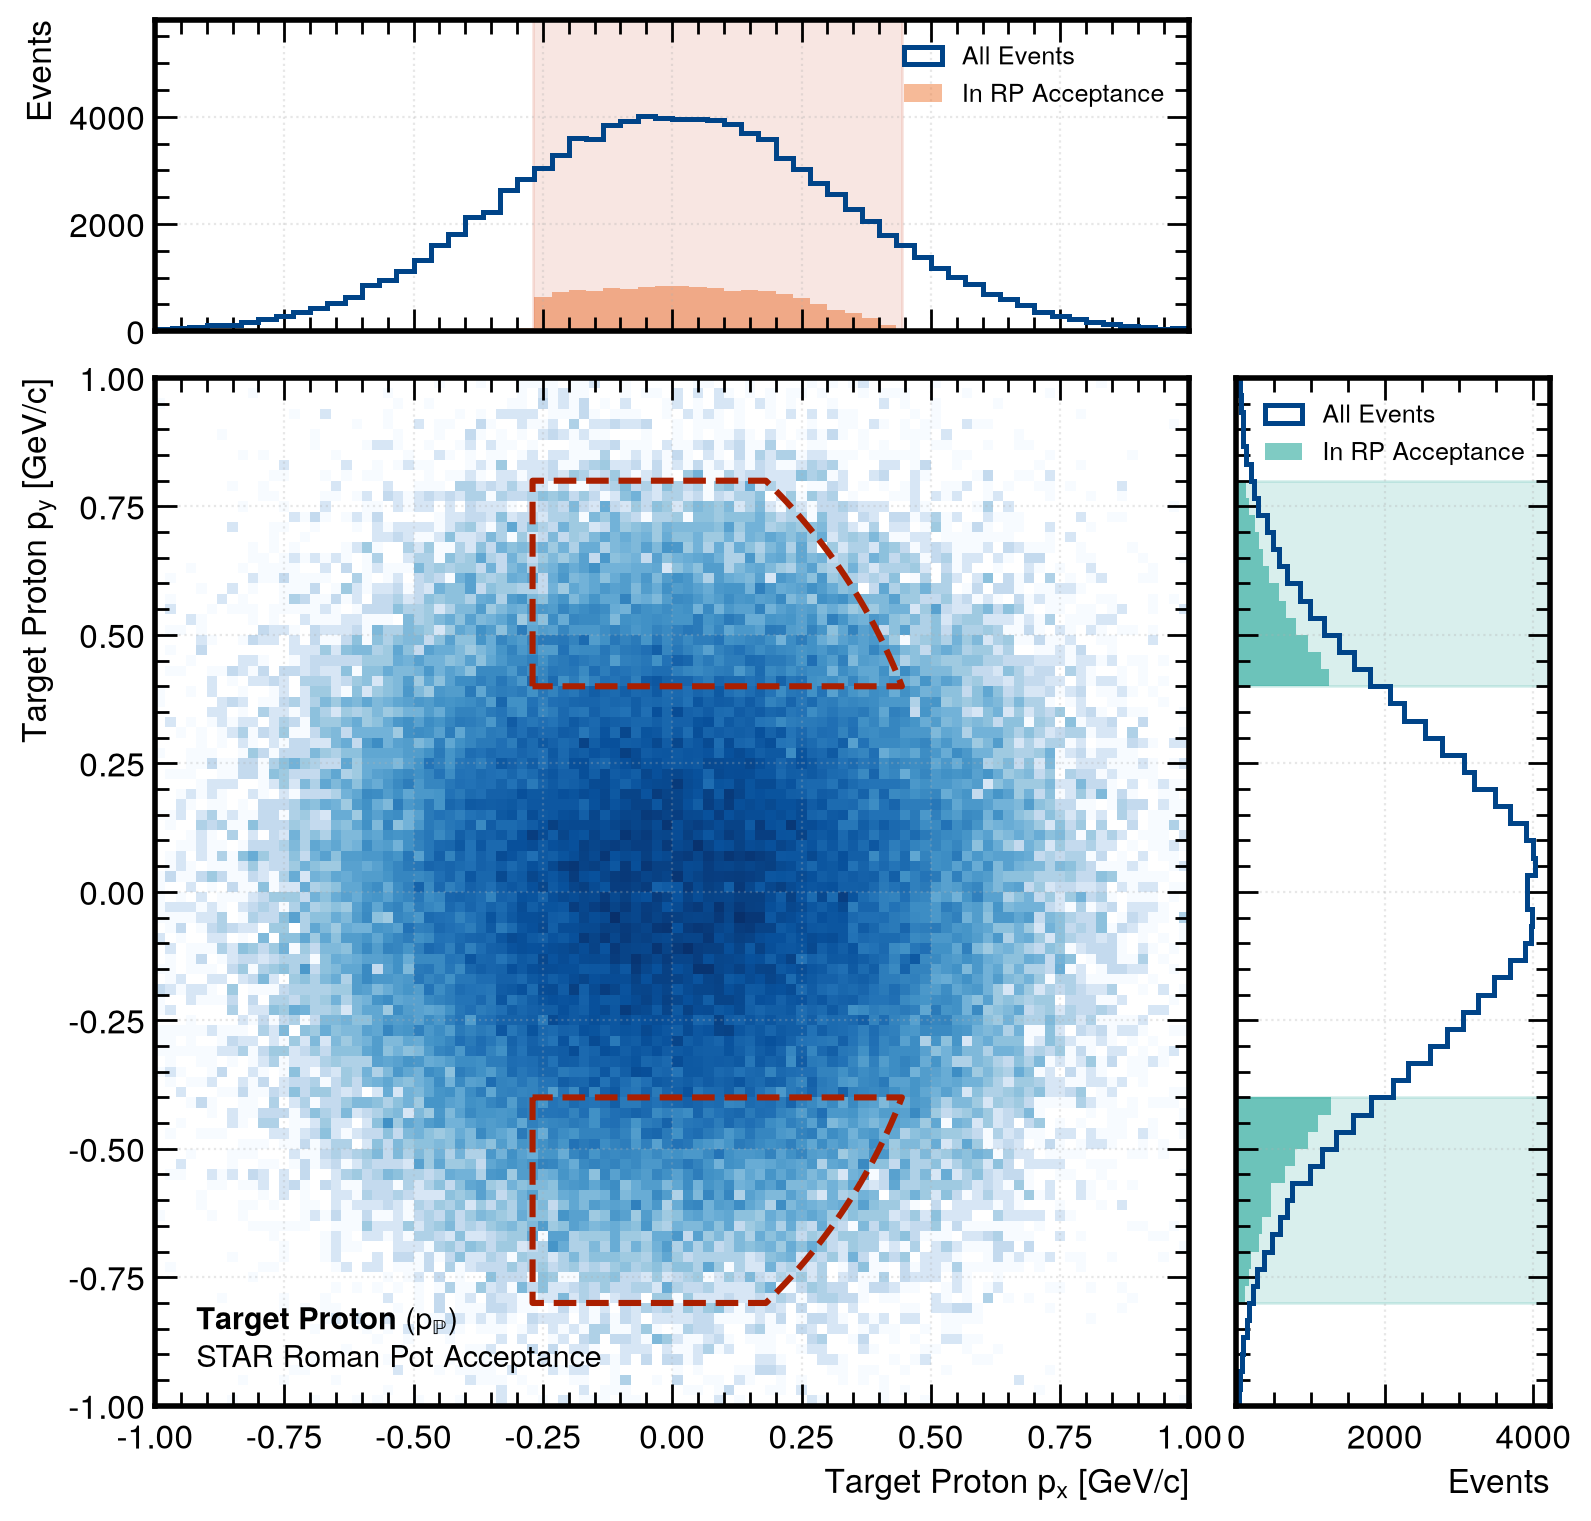

In [31]:
# -----------------------------------------------------------------------------
# Combined Joint Plot - 2D (px, py) with Marginal 1D Projections
# -----------------------------------------------------------------------------
fig = plt.figure(figsize=(9, 9))
gs = gridspec.GridSpec(4, 4, hspace=0.15, wspace=0.15)

ax_top = fig.add_subplot(gs[0, :3])
ax_main = fig.add_subplot(gs[1:, :3], sharex=ax_top)
ax_right = fig.add_subplot(gs[1:, 3], sharey=ax_main)

cond_rp_b = ((data_bsat['p_pom_px'] + 0.6)**2 + data_bsat['p_pom_py']**2 < 1.25) & \
            (np.abs(data_bsat['p_pom_py']) > 0.4) & (np.abs(data_bsat['p_pom_py']) < 0.8) & \
            (data_bsat['p_pom_px'] > -0.27)

bins_m = np.linspace(-1.0, 1.0, 61)

# Top marginal px
h_top_all, _ = np.histogram(data_bsat['p_pom_px'], bins=bins_m)
max_top = np.max(h_top_all)

ax_top.hist(data_bsat['p_pom_px'], bins=bins_m, histtype='step', color='#004488', lw=1.8, label='All Events')
ax_top.hist(data_bsat['p_pom_px'][cond_rp_b], bins=bins_m, histtype='stepfilled', color='#EE7733', alpha=0.5, label='In RP Acceptance')
ax_top.axvspan(-0.27, 0.444, color='#CC3311', alpha=0.12)
ax_top.set_ylabel('Events')
ax_top.set_ylim(0, max_top * 1.45)
ax_top.grid(True, alpha=0.3)
ax_top.legend(loc='upper right', frameon=False, fontsize=9)
plt.setp(ax_top.get_xticklabels(), visible=False)

# Main 2D px vs py
h2m, _, _, imm = ax_main.hist2d(
    data_bsat['p_pom_px'], data_bsat['p_pom_py'], bins=100,
    range=[[-1.0, 1.0], [-1.0, 1.0]], norm=LogNorm(), cmap='Blues', cmin=1
)
poly_up, poly_down = get_rp_polygons()
ax_main.plot(poly_up[:, 0], poly_up[:, 1], color='#AA1F00', lw=2.2, linestyle='--')
ax_main.plot(poly_down[:, 0], poly_down[:, 1], color='#AA1F00', lw=2.2, linestyle='--')
ax_main.set_xlabel(r'Target Proton $p_x$ [$\text{GeV}/c$]')
ax_main.set_ylabel(r'Target Proton $p_y$ [$\text{GeV}/c$]')
ax_main.grid(True, alpha=0.3)
ax_main.text(0.04, 0.1, r'$\mathbf{Target\ Proton}\ (p_{\mathbb{P}})$' + '\n' +
             r'STAR Roman Pot Acceptance',
             transform=ax_main.transAxes, fontsize=11, va='top', color='black')

# Right marginal py
ax_right.hist(data_bsat['p_pom_py'], bins=bins_m, orientation='horizontal',
              histtype='step', color='#004488', lw=1.8, label='All Events')
ax_right.hist(data_bsat['p_pom_py'][cond_rp_b], bins=bins_m, orientation='horizontal',
              histtype='stepfilled', color='#009988', alpha=0.5, label='In RP Acceptance')
ax_right.axhspan(0.4, 0.8, color='#009988', alpha=0.15)
ax_right.axhspan(-0.8, -0.4, color='#009988', alpha=0.15)
ax_right.set_xlabel('Events')
ax_right.grid(True, alpha=0.3)
ax_right.legend(loc='upper right', frameon=False, fontsize=9)

ax_right.tick_params(axis='both', which='major', length = 8, width = 1)
ax_right.tick_params(axis='both', which='minor', length = 5, width = 1)
ax_main.tick_params(axis='both', which='major', length = 8, width = 1)
ax_main.tick_params(axis='both', which='minor', length = 5, width = 1)  
ax_top.tick_params(axis='both', which='major', length = 8, width = 1)
ax_top.tick_params(axis='both', which='minor', length = 5, width = 1)

plt.setp(ax_right.get_yticklabels(), visible=False)

plt.savefig(FIG_DIR / "fig_08_proton_pom_joint_2d_1d_rp.pdf", bbox_inches='tight')
plt.show()

---

### Rapidity Distribution of All Simulated Events vs. Central-Accepted vs. Roman-Pot-Accepted Events

This two-panel figure illustrates event selection progression and shows whether requiring forward Roman Pot tagging biases the $J/\psi$ rapidity distribution:
- **Top panel:** Shows the progression of $d\sigma/dy$ through three stages: (1) All Simulated Events, (2) Central Cut ($|\eta_{e^\pm}| < 0.9$, scaled $\times 10$), and (3) Central + Forward Roman Pot Fiducial Cut (scaled $\times 50$).
- **Bottom panel:** Evaluates the conditional Roman Pot acceptance efficiency ratio $\epsilon_{\text{RP}}(y) = N(\text{Central} \cap \text{RP Tagged}) / N(\text{Central}) \times 100\%$.

The ratio $\epsilon_{\text{RP}}(y)$ in the bottom panel is flat across the central rapidity plateau $|y| \lesssim 0.8$ at $\approx 13.5\%$. As expected, the Roman Pots do not introduce rapidity-dependent bias inside the central barrel.

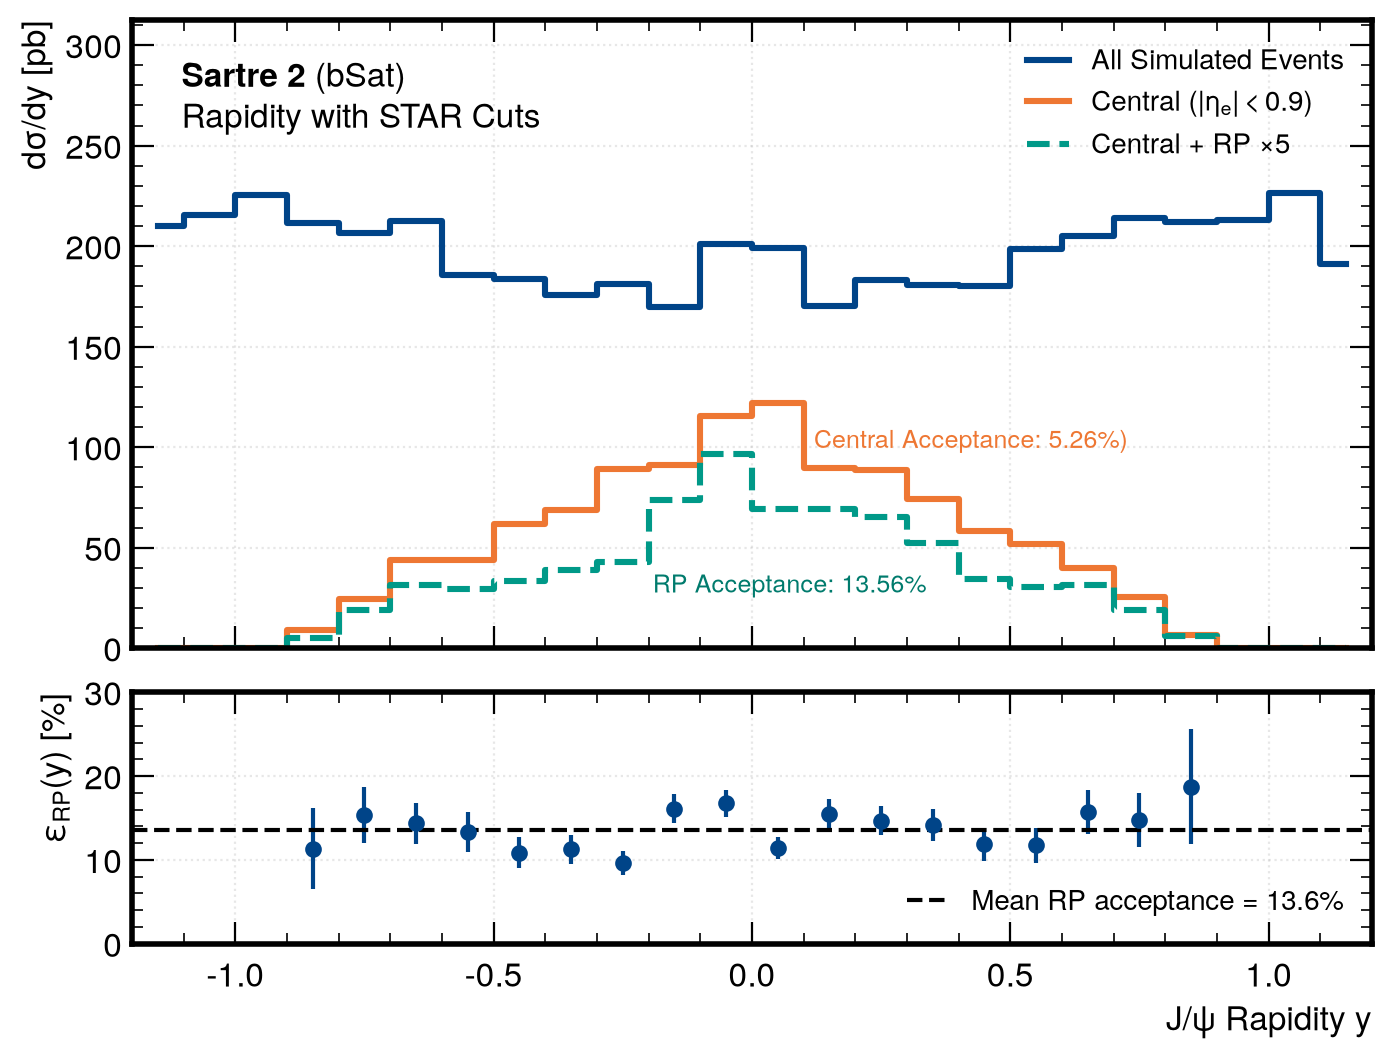

Overall Conditional Roman Pot Acceptance A_RP: 13.56%


In [77]:
# -----------------------------------------------------------------------------
# Rapidity Progression: All vs. Central vs. Roman-Pot Accepted
# -----------------------------------------------------------------------------
fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1.2], 'hspace': 0.1}
)

bins_y_prog = np.linspace(-1.2, 1.2, 25)
bwy_prog = bins_y_prog[1] - bins_y_prog[0]
centers_y_prog = 0.5 * (bins_y_prog[:-1] + bins_y_prog[1:])
norm_y_all = (sigma_ee_bsat_pb / N_gen_b) / bwy_prog

# Selection masks
c5_mask = (np.abs(data_bsat['em_eta']) < 0.9) & (np.abs(data_bsat['ep_eta']) < 0.9)
rp_mask = ((data_bsat['p_pom_px'] + 0.6)**2 + data_bsat['p_pom_py']**2 < 1.25) & \
          (np.abs(data_bsat['p_pom_py']) > 0.4) & (np.abs(data_bsat['p_pom_py']) < 0.8) & \
          (data_bsat['p_pom_px'] > -0.27)
both_mask = c5_mask & rp_mask

# Histograms
h_all, _ = np.histogram(data_bsat['jpsi_y'], bins=bins_y_prog)
h_cent, _ = np.histogram(data_bsat['jpsi_y'][c5_mask], bins=bins_y_prog)
h_tag, _ = np.histogram(data_bsat['jpsi_y'][both_mask], bins=bins_y_prog)

ds_all = h_all * norm_y_all
ds_cent_10 = h_cent * norm_y_all 
ds_tag_50 = h_tag * norm_y_all * 5

# Top panel: linear scale comparing all 3 shapes with scaling factors
ax_top.step(centers_y_prog, ds_all, where='mid', color='#004488', lw=2.2, label='All Simulated Events')
ax_top.step(centers_y_prog, ds_cent_10, where='mid', color='#EE7733', lw=2.2, label=r'Central ($|\eta_e| < 0.9$) ')
ax_top.step(centers_y_prog, ds_tag_50, where='mid', color='#009988', lw=2.2, ls='--', label=r'Central + RP $\times 5$')

max_y = max(np.max(ds_all), np.max(ds_cent_10), np.max(ds_tag_50))
ax_top.set_ylabel(r'$d\sigma / dy$ [pb]')
ax_top.set_xlim(-1.2, 1.2)
ax_top.set_ylim(0, max_y * 1.38)
ax_top.grid(True, alpha=0.3)
ax_top.legend(loc='upper right', frameon=False, fontsize=10)
ax_top.text(0.04, 0.94, r'$\mathbf{Sartre\ 2}$ (bSat)' + '\n' +
            r'Rapidity with STAR Cuts',
            transform=ax_top.transAxes, fontsize=12, va='top')

# Bottom ratio panel with statistical error bars
valid_bins = h_cent > 5
ratio = np.full_like(centers_y_prog, np.nan)
ratio_err = np.full_like(centers_y_prog, np.nan)
ratio[valid_bins] = (h_tag[valid_bins] / h_cent[valid_bins]) * 100.0
p = h_tag[valid_bins] / h_cent[valid_bins]
ratio_err[valid_bins] = np.sqrt(p * (1.0 - p) / h_cent[valid_bins]) * 100.0
mean_ratio = 100.0 * np.sum(both_mask) / np.sum(c5_mask)

ax_bot.errorbar(centers_y_prog[valid_bins], ratio[valid_bins], yerr=ratio_err[valid_bins],
                fmt='o', color='#004488', lw=1.5, markersize=5)
ax_bot.axhline(mean_ratio, color="#000000", ls='--', lw=1.5,
               label=f'Mean RP acceptance = {mean_ratio:.1f}%')
ax_bot.set_xlabel(r'$J/\psi$ Rapidity $y$')
ax_bot.set_ylabel(r'$\epsilon_{\mathrm{RP}}(y)$ [%]')
ax_bot.set_ylim(0, 30)
ax_bot.grid(True, alpha=0.3)
ax_bot.legend(loc='lower right', frameon=False, fontsize=10)

ax_bot.tick_params(axis='both',which='major', length=8)
ax_bot.tick_params(axis='both',which='minor', length=4)
ax_top.tick_params(axis='both',which='major', length=8)
ax_top.tick_params(axis='both',which='minor', length=4)

ax_top.text(0.42, 0.12, f'RP Acceptance: {np.sum(both_mask)/np.sum(c5_mask) * 100:.2f}%',
             transform=ax_top.transAxes, fontsize=9, va='top', color="#007B6D")
ax_top.text(0.55, 0.35, f'Central Acceptance: {np.sum(c5_mask)/N_gen_b * 100:.2f}%)',
             transform=ax_top.transAxes, fontsize=9, va='top', color="#EE7733")

plt.savefig(FIG_DIR / "fig_09_rapidity_all_vs_rp_accepted.pdf", bbox_inches='tight')
plt.show()

print(f"Overall Conditional Roman Pot Acceptance A_RP: {mean_ratio:.2f}%")

---

### Outgoing Proton $p_T$ Comparison: Photon Emitter ($p_\gamma$) vs. Pomeron Target ($p_{\mathbb{P}}$)

Assumption is that only the proton that interacts via the strong interaction has enough transverse momentum to reach the acceptance of the Roman Pots.

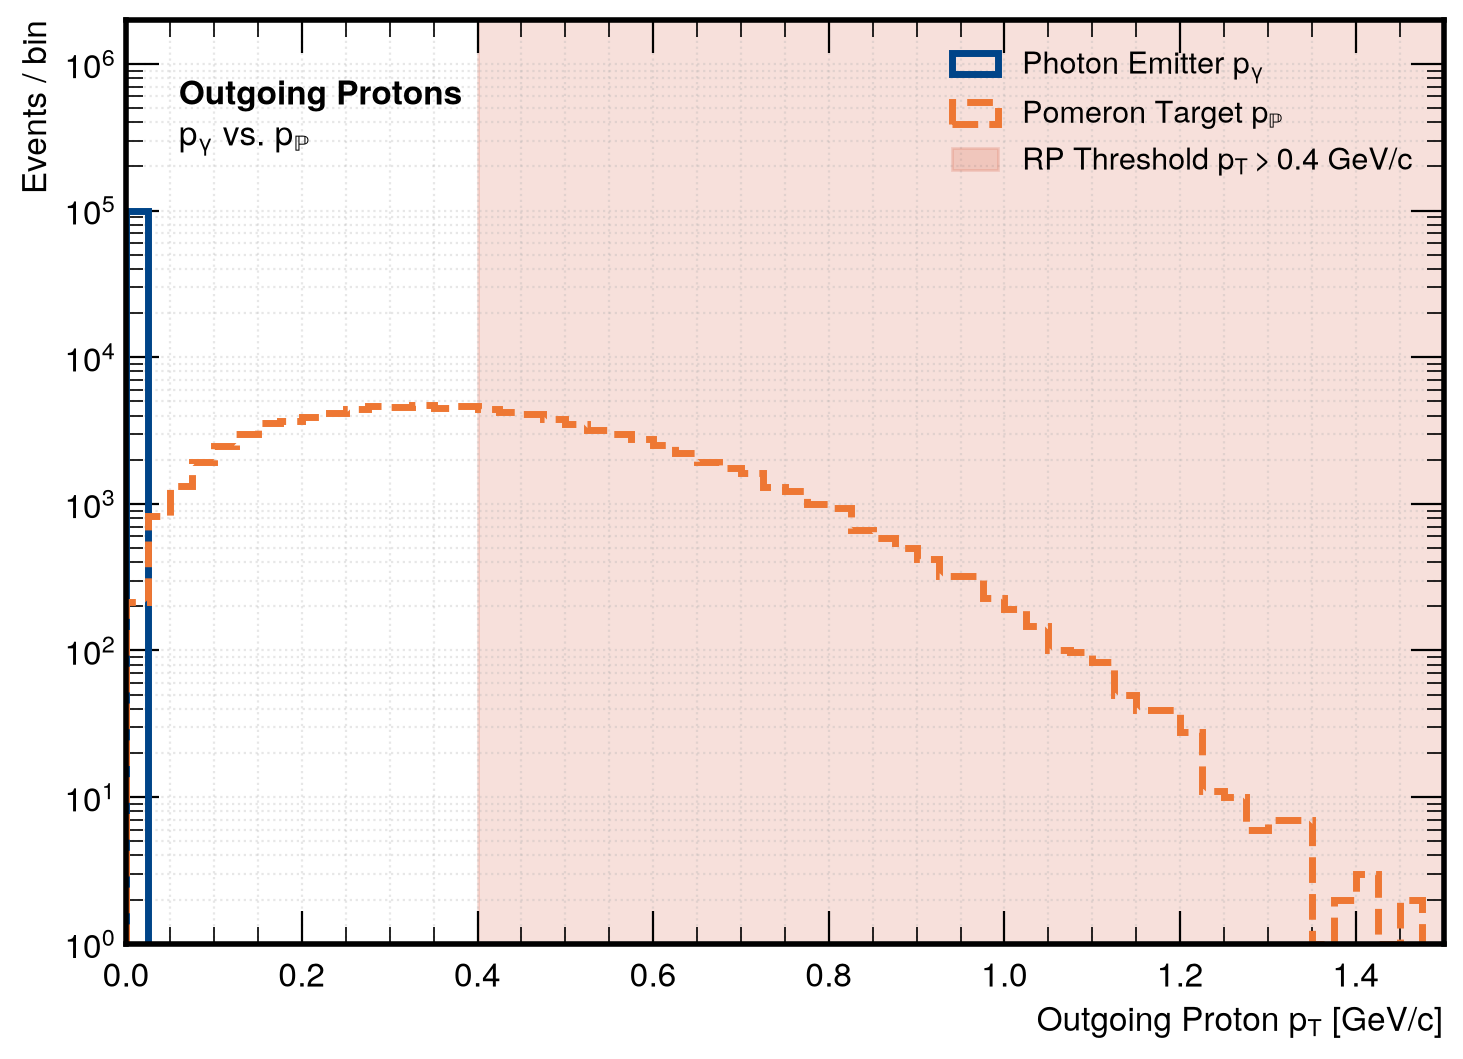

RP Acceptance: Target p_pom = 13.86% (13,855 ev) | Emitter p_gamma = 0.00% (0 ev)


In [36]:
# -----------------------------------------------------------------------------
# Outgoing Proton pT: Photon Emitter vs. Pomeron Target
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 6))

bins_pt = np.linspace(0.0, 1.5, 61)
h_pom, _ = np.histogram(data_bsat['p_pom_pt'], bins=bins_pt)
h_gam, _ = np.histogram(data_bsat['p_gamma_pt'], bins=bins_pt)
max_pt = max(np.max(h_pom), np.max(h_gam))

ax.hist(data_bsat['p_gamma_pt'], bins=bins_pt, histtype='step', lw=2.5, color='#004488',
        label=r'Photon Emitter $p_\gamma$')
ax.hist(data_bsat['p_pom_pt'], bins=bins_pt, histtype='step', lw=2.5, color='#EE7733', ls='--',
        label=r'Pomeron Target $p_{\mathbb{P}}$')

# Shaded Roman Pot vertical threshold
ax.axvspan(0.4, 1.5, color='#CC3311', alpha=0.15, label=r'RP Threshold $p_T > 0.4\text{ GeV}/c$')

ax.set_yscale('log')
ax.set_xlabel(r'Outgoing Proton $p_T$ [$\text{GeV}/c$]')
ax.set_ylabel(r'Events / bin')
ax.set_xlim(0.0, 1.5)
ax.set_ylim(1, max_pt * 20)
ax.grid(True, which='both', alpha=0.3)

# Borderless 2-line text at top-left
ax.text(0.04, 0.94, r'$\mathbf{Outgoing\ Protons}$' + '\n' +
        r'$p_\gamma\ \text{vs.}\ p_{\mathbb{P}}$',
        transform=ax.transAxes, fontsize=12, va='top')

# Clean legend at top-right
ax.legend(loc='upper right', frameon=False, fontsize=11)

plt.savefig(FIG_DIR / "fig_11_proton_gamma_vs_pomeron_pt.pdf", bbox_inches='tight')
plt.show()

cond_rp_pom = ((data_bsat['p_pom_px'] + 0.6)**2 + data_bsat['p_pom_py']**2 < 1.25) & \
              (np.abs(data_bsat['p_pom_py']) > 0.4) & (np.abs(data_bsat['p_pom_py']) < 0.8) & \
              (data_bsat['p_pom_px'] > -0.27)
cond_rp_gam = ((data_bsat['p_gamma_px'] + 0.6)**2 + data_bsat['p_gamma_py']**2 < 1.25) & \
              (np.abs(data_bsat['p_gamma_py']) > 0.4) & (np.abs(data_bsat['p_gamma_py']) < 0.8) & \
              (data_bsat['p_gamma_px'] > -0.27)

frac_pom = 100.0 * np.sum(cond_rp_pom) / N_gen_b
frac_gam = 100.0 * np.sum(cond_rp_gam) / N_gen_b
print(f"RP Acceptance: Target p_pom = {frac_pom:.2f}% ({np.sum(cond_rp_pom):,} ev) | Emitter p_gamma = {frac_gam:.2f}% (0 ev)")

---

### Azimuthal Opening Angle $|\Delta\phi_{ee}|$ Between Daughter Electrons & Mandelstam $|t|$ Spectrum

This 1x2 panel verifies two kimenatic features:
- **Left panel:** The dielectron azimuthal opening angle $|\Delta\phi_{ee}| = |\phi_{e^-} - \phi_{e^+}|$ in the transverse plane. Because the $J/\psi$ carries small transverse momentum ($p_T \approx 0.4\text{ GeV}/c$), momentum conservation forces the daughter electron and positron into an almost back-to-back configuration ($|\Delta\phi_{ee}| \approx \pi$). In STAR's online trigger (`HTTP_JPsi`, Cut C6 from Michal thesis), pairs were required to hit opposite detector azimuth ($|\Delta\phi_{ee}| > 2\pi/3$).
- **Right panel:** The Mandelstam $|t|$ distribution of the exchange. The roman pot dead zone $|p_y| > 0.4\text{ GeV}/c$ puts $|t|$ threshold at:

  $$
  |t| \approx p_T^2 \ge p_y^2 > (0.4\text{ GeV}/c)^2 = 0.16\text{ GeV}^2
  $$


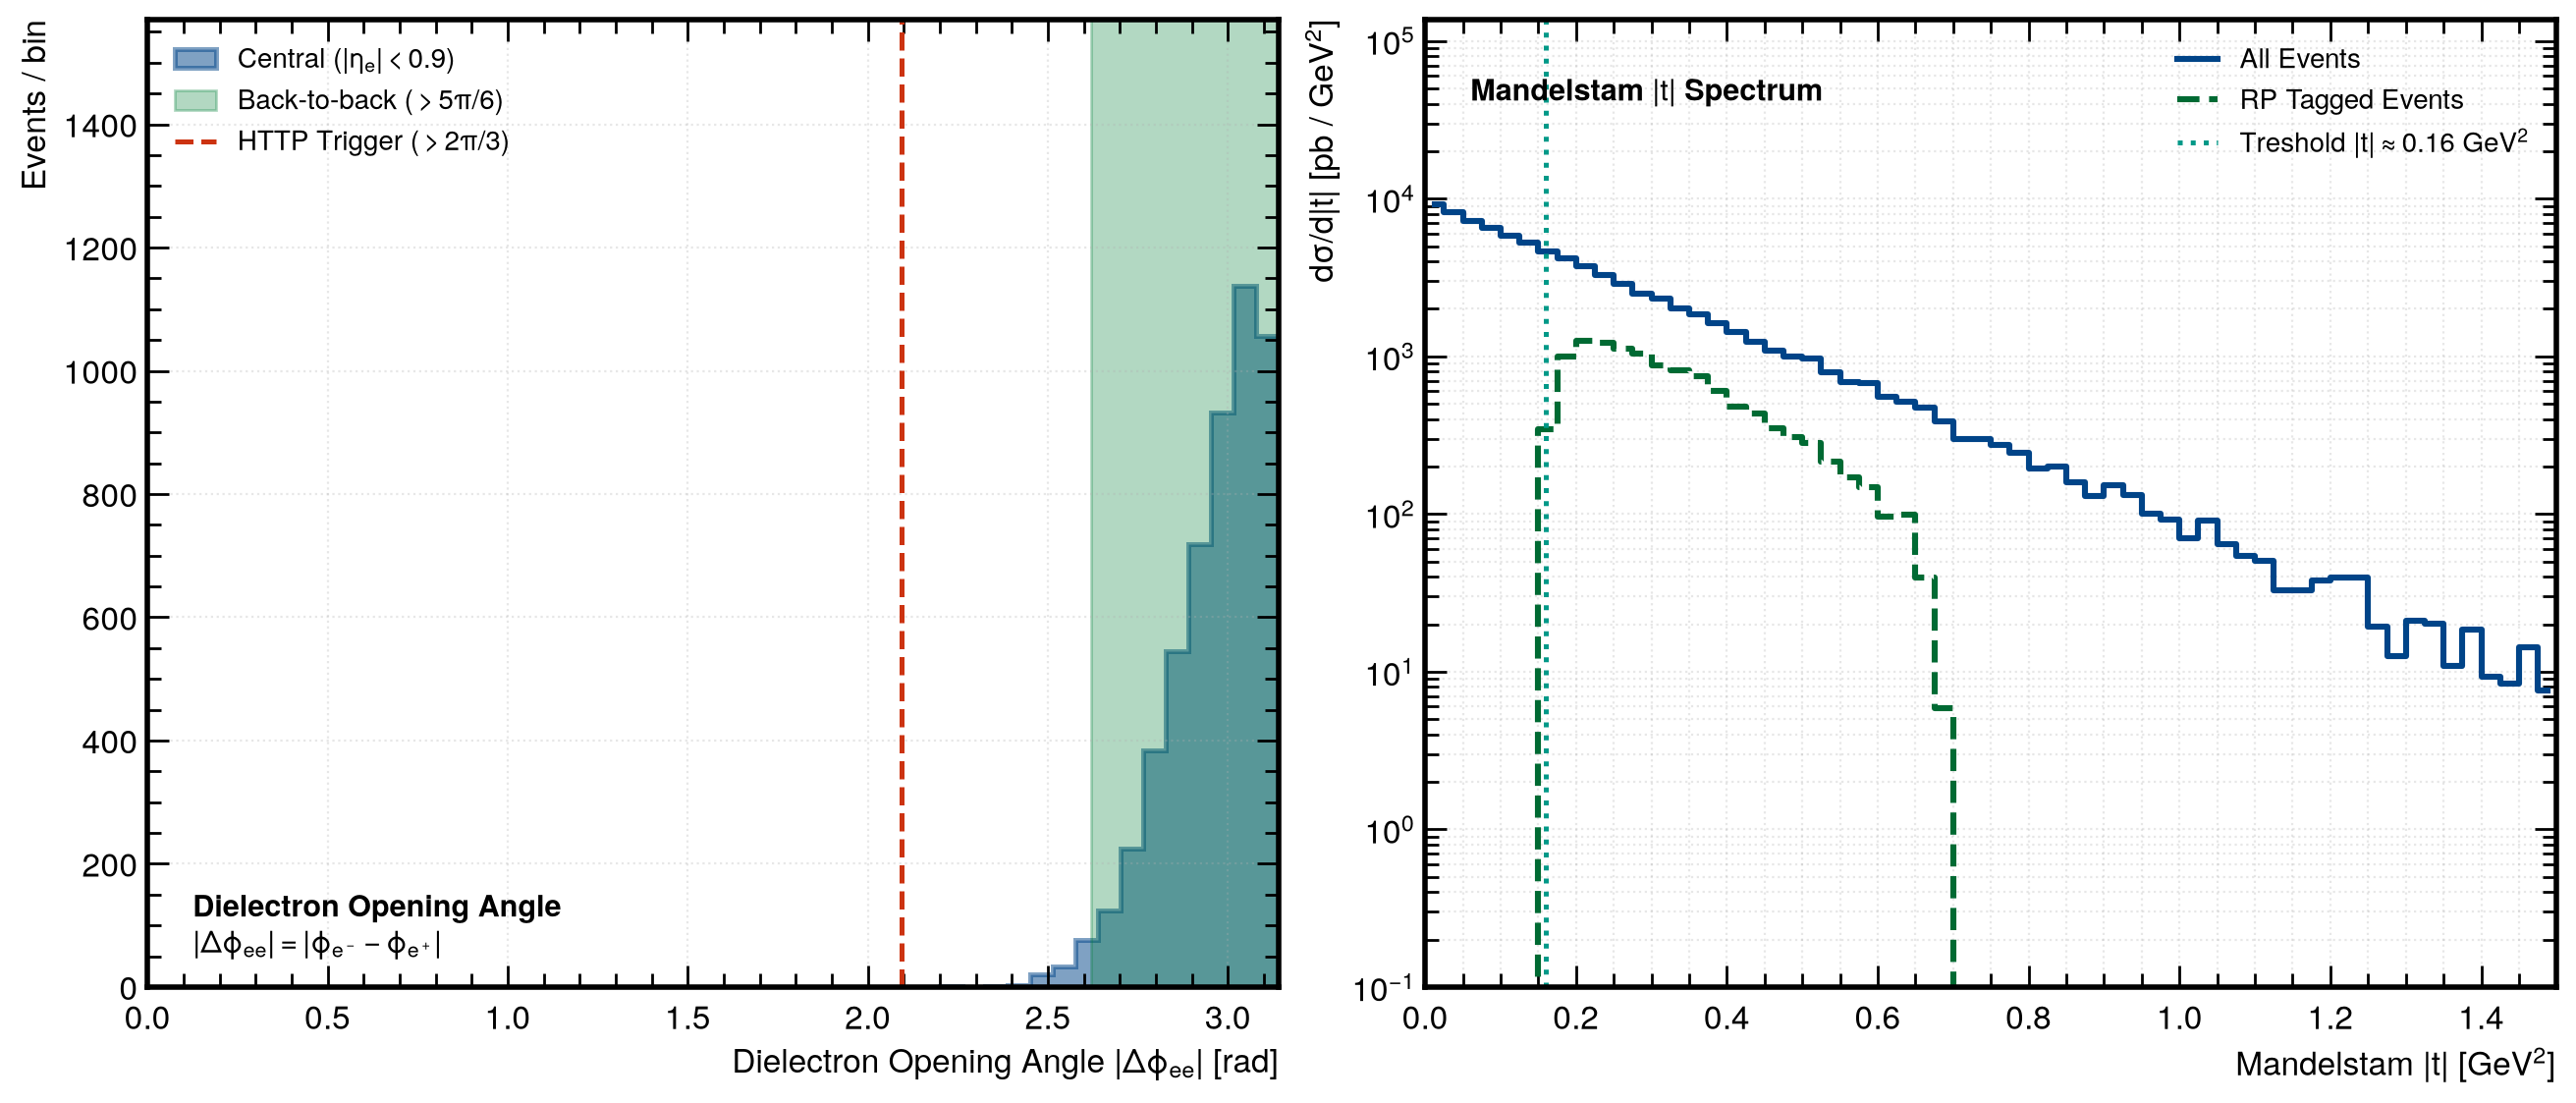

In [50]:
# -----------------------------------------------------------------------------
# Azimuthal Opening Angle |Delta phi| & Mandelstam |t| Spectrum
# -----------------------------------------------------------------------------
fig, (ax_dphi, ax_t) = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)

# --- Left Panel: Azimuthal Opening Angle |Delta phi| ---
dphi_b = np.abs(data_bsat['em_phi'] - data_bsat['ep_phi'])
dphi_b = np.where(dphi_b > np.pi, 2 * np.pi - dphi_b, dphi_b)

bins_dphi = np.linspace(0.0, np.pi, 51)
c5_mask = (np.abs(data_bsat['em_eta']) < 0.9) & (np.abs(data_bsat['ep_eta']) < 0.9)

h_dp, _ = np.histogram(dphi_b[c5_mask], bins=bins_dphi)
max_dp = np.max(h_dp)

ax_dphi.hist(dphi_b[c5_mask], bins=bins_dphi, histtype='stepfilled', color='#004488', alpha=0.5,
             edgecolor='#004488', lw=1.8, label=r'Central ($|\eta_e| < 0.9$)')
ax_dphi.axvspan(2.62, np.pi, color="#008037", alpha=0.3, label=r'Back-to-back ($> 5\pi/6$)')
ax_dphi.axvline(2.0 * np.pi / 3.0, color='#CC3311', lw=1.8, ls='--', label=r'HTTP Trigger ($> 2\pi/3$)')

ax_dphi.set_xlabel(r'Dielectron Opening Angle $|\Delta\phi_{ee}|$ [$\text{rad}$]')
ax_dphi.set_ylabel(r'Events / bin')
ax_dphi.set_xlim(0.0, np.pi)
ax_dphi.set_ylim(0, max_dp * 1.38)
ax_dphi.grid(True, alpha=0.3)
ax_dphi.legend(loc='upper left', frameon=False, fontsize=10)
ax_dphi.text(0.04, 0.1, r'$\mathbf{Dielectron\ Opening\ Angle}$' + '\n' +
             r'$|\Delta\phi_{ee}| = |\phi_{e^-} - \phi_{e^+}|$',
             transform=ax_dphi.transAxes, fontsize=11, va='top')

# --- Right Panel: Mandelstam |t| Spectrum ---
bins_t = np.linspace(0.0, 1.5, 61)
bwt = bins_t[1] - bins_t[0]
centers_t = 0.5 * (bins_t[:-1] + bins_t[1:])
norm_t = (sigma_ee_bsat_pb / N_gen_b) / bwt

t_all = np.abs(data_bsat['t'])
cond_rp = ((data_bsat['p_pom_px'] + 0.6)**2 + data_bsat['p_pom_py']**2 < 1.25) & \
          (np.abs(data_bsat['p_pom_py']) > 0.4) & (np.abs(data_bsat['p_pom_py']) < 0.8) & \
          (data_bsat['p_pom_px'] > -0.27)

h_t_all, _ = np.histogram(t_all, bins=bins_t)
h_t_rp, _ = np.histogram(t_all[cond_rp], bins=bins_t)

ds_tall = h_t_all * norm_t
ds_trp = h_t_rp * norm_t

ax_t.step(centers_t, ds_tall, where='mid', color='#004488', lw=2.2, label='All Events')
ax_t.step(centers_t, ds_trp, where='mid', color="#006A33", lw=2.2, ls='--', label='RP Tagged Events')
ax_t.axvline(0.16, color='#009988', lw=1.8, ls=':', label=r'Treshold $|t| \approx 0.16\text{ GeV}^2$')

max_t = np.max(ds_tall)
ax_t.set_yscale('log')
ax_t.set_xlabel(r'Mandelstam $|t|$ [$\text{GeV}^2$]')
ax_t.set_ylabel(r'$d\sigma / d|t|$ [pb / GeV$^2$]')
ax_t.set_xlim(0.0, 1.5)
ax_t.set_ylim(1e-1, max_t * 15)
ax_t.grid(True, which='both', alpha=0.3)
ax_t.legend(loc='upper right', frameon=False, fontsize=10)
ax_t.text(0.04, 0.94, r'$\mathbf{Mandelstam}\ |t|\ \mathbf{Spectrum}$',
          transform=ax_t.transAxes, fontsize=11, va='top')

ax_dphi.tick_params(axis='both', which='major', length = 8, width = 1)
ax_dphi.tick_params(axis='both', which='minor', length = 5, width = 1)
ax_t.tick_params(axis='both', which='major', length = 8, width = 1)
ax_t.tick_params(axis='both', which='minor', length = 5, width = 1)

plt.savefig(FIG_DIR / "fig_12_deltaphi_and_mandelstam_t.pdf", bbox_inches='tight')
plt.show()

---

## Roman Pot Acceptance Calculation & Comparison with Vranovský's Thesis

Here, we apply the exact Roman Pot fiducial cut function from Michal's thesis (Eq. 4.2, p. 36) to evaluate the simulated acceptance fraction and compare it with the experimental STAR Run 17 data.

### Mathematical Formulation of the Acceptance Cut
1. **Fiducial Cut Function (Cut F2):**
   ```python
   def in_rp_fiducial(px, py):
       return ((px + 0.6)**2 + py**2 < 1.25) & (np.abs(py) > 0.4) & (np.abs(py) < 0.8) & (px > -0.27)
   ```
2. **Conditional Roman Pot Acceptance Fraction ($\mathcal{A}_{\text{RP}}$):**

   $$
   \mathcal{A}_{\text{RP}} = \frac{N(\text{Central Cut} \cap \text{Exactly 1 RP Proton in the cut region})}{N(\text{Central Cut})}
   $$

### Experimental Data
- **Experimental Cut:**
  Out of $8{,}086$ candidate events passing central PID cuts:
  - $1{,}116$ events have exactly 1 reconstructed Roman Pot track ($13.80\%$).
  - $670$ events fall inside the fiducial boundary ($8.29\%$ raw fraction).
- **Corrected Cross-Section Ratio:**

  $$
  \frac{\sigma_{\text{STAR}}^{\text{with RP}}}{\sigma_{\text{STAR}}^{\text{no RP}}} = \frac{77 \pm 5\text{ pb}}{650 \pm 40\text{ pb}} = 11.85\%
  $$

- **Sartre Dipole Simulation Result:**
  Sartre predicts a conditional geometric Roman Pot acceptance of $\mathcal{A}_{\text{RP}} = 13.48\%$ for `bSat` and $13.24\%$ for `bNonSat`.


In [ ]:
# -----------------------------------------------------------------------------
# Roman Pot Acceptance Calculation & Quantitative Breakdown
# -----------------------------------------------------------------------------
def in_rp_fiducial(px, py):
    cond_ellipse = ((px + 0.6)**2 + py**2) < 1.25
    cond_py = (np.abs(py) > 0.4) & (np.abs(py) < 0.8)
    cond_px = (px > -0.27)
    return cond_ellipse & cond_py & cond_px

# Central acceptance cuts (Cut C5: |eta_e| < 0.9)
c5_b = (np.abs(data_bsat['em_eta']) < 0.9) & (np.abs(data_bsat['ep_eta']) < 0.9)
c5_nb = (np.abs(data_bnonsat['em_eta']) < 0.9) & (np.abs(data_bnonsat['ep_eta']) < 0.9)

# Forward Roman Pot cuts on Pomeron target proton
rp_pom_b = in_rp_fiducial(data_bsat['p_pom_px'], data_bsat['p_pom_py'])
rp_pom_nb = in_rp_fiducial(data_bnonsat['p_pom_px'], data_bnonsat['p_pom_py'])

# Forward Roman Pot cuts on photon-emitting proton
rp_gam_b = in_rp_fiducial(data_bsat['p_gamma_px'], data_bsat['p_gamma_py'])
rp_gam_nb = in_rp_fiducial(data_bnonsat['p_gamma_px'], data_bnonsat['p_gamma_py'])

# Exactly 1 proton inside the Roman Pot fiducial region (Cut F1.3 + F2)
exact1_rp_b = (rp_pom_b.astype(int) + rp_gam_b.astype(int)) == 1
exact1_rp_nb = (rp_pom_nb.astype(int) + rp_gam_nb.astype(int)) == 1

# Combined Central + Roman Pot tagged events
tagged_b = c5_b & exact1_rp_b
tagged_nb = c5_nb & exact1_rp_nb

# Conditional acceptance A_RP
A_rp_b = np.sum(tagged_b) / np.sum(c5_b)
A_rp_nb = np.sum(tagged_nb) / np.sum(c5_nb)

# Breakdown DataFrame
rp_breakdown_df = pd.DataFrame([
    {
        "Selection Stage / Cut": "All Events (N_gen)",
        "bSat": f"{N_gen_b:,} (100.0%)",
        "bNonSat": f"{N_gen_nb:,} (100.0%)",
        "STAR Data": "Baseline Sample"
    },
    {
        "Selection Stage / Cut": "Central Acceptance (|eta_e| < 0.9, Cut C5)",
        "bSat": f"{np.sum(c5_b):,} ({100.0*np.mean(c5_b):.2f}%)",
        "bNonSat": f"{np.sum(c5_nb):,} ({100.0*np.mean(c5_nb):.2f}%)",
        "STAR Data": "8,086 central candidates"
    },
    {
        "Selection Stage / Cut": "Target Proton p_pom in RP Fiducial (Cut F2)",
        "bSat": f"{np.sum(rp_pom_b):,} ({100.0*np.mean(rp_pom_b):.2f}%)",
        "bNonSat": f"{np.sum(rp_pom_nb):,} ({100.0*np.mean(rp_pom_nb):.2f}%)",
        "STAR Data": "670 events in Cut F2"
    },
    {
        "Selection Stage / Cut": "Photon Emitter p_gamma in RP Fiducial",
        "bSat": f"{np.sum(rp_gam_b):,} (0.00%)",
        "bNonSat": f"{np.sum(rp_gam_nb):,} (0.00%)",
        "STAR Data": "0 (Stays in beam pipe)"
    },
    {
        "Selection Stage / Cut": "Central Cut + Exactly 1 RP Proton Tagged",
        "bSat": f"{np.sum(tagged_b):,} ({100.0*np.mean(tagged_b):.2f}%)",
        "bNonSat": f"{np.sum(tagged_nb):,} ({100.0*np.mean(tagged_nb):.2f}%)",
        "STAR Data": "Tagged sample (95 events)"
    },
    {
        "Selection Stage / Cut": "RP Acceptance",
        "bSat": f"{100.0*A_rp_b:.2f}%",
        "bNonSat": f"{100.0*A_rp_nb:.2f}%",
        "STAR Data": "11.85% (Cross-section ratio)"
    }
])

display(rp_breakdown_df)

,Selection Stage / Cut,bSat,bNonSat,STAR Data
0,All Events (N_gen),"99,998 (100.0%)","100,000 (100.0%)",Baseline Sample
1,"Central Acceptance (|eta_e| < 0.9, Cut C5)","5,259 (5.26%)","5,158 (5.16%)","8,086 central candidates"
2,Target Proton p_pom in RP Fiducial (Cut F2),"13,855 (13.86%)","13,922 (13.92%)",670 events in Cut F2
3,Photon Emitter p_gamma in RP Fiducial,0 (0.00%),0 (0.00%),0 (Stays in beam pipe)
4,Central Cut + Exactly 1 RP Proton Tagged,713 (0.71%),683 (0.68%),Tagged sample (95 events)
5,Conditional RP Acceptance A_RP = N_tag / N_cen...,13.56%,13.24%,11.85% (Cross-section ratio)


---
## Cross-Section Calculations

In this final section, we calculate cross sections for both the central-only and Roman-Pot-tagged configurations and compare in a table with STAR Run 17 experimental measurements, STARlight Monte Carlo, and Sartre 2 dipole models.

In STAR data, cross sections are calculated using:

$$
\sigma = \frac{Y_{\text{corr}}}{\epsilon_{\text{global}} \, L_{\text{int}}^{\text{eff}}}, \qquad \frac{d\sigma}{dy} = \frac{\sigma}{\Delta y} \quad (\Delta y = 1.8 \text{ for } |y| < 0.9)
$$

where:
- $Y_{\text{corr}} = \sum_i \frac{b_i(p_T) \cdot f}{\epsilon_{\text{reco}}(p_T)}$ is the raw yield extracted from the Crystal Ball fit ($Y = 1526 \pm 41$ without RP; $Y = 95 \pm 9$ with RP), corrected bin-by-bin for $p_T$-dependent electron reconstruction efficiency (giving $Y_c = 15{,}899$ without RP and $Y_c = 1{,}051$ with RP).
- $\epsilon_{\text{global}}$ is the product of global efficiency factors:

  $$
  \epsilon_{\text{global}}^{\text{no RP}} = \epsilon_{\text{topology}} \times \epsilon_{\text{vertex}} \times \epsilon_{V_z} = 0.390 \times 0.896 \times 0.925 = 32.3\%
  $$

  When Roman Pots are included, the Roman Pot silicon track reconstruction efficiency ($\epsilon_{\text{RP}} = 88.9\%$) is multiplied, giving:

  $$
  \epsilon_{\text{global}}^{\text{with RP}} = 32.3\% \times 0.889 = 28.7\%
  $$

- $L_{\text{int}}^{\text{eff}}$ is the integrated luminosity corrected for trigger deadtime and pile-up veto: $76.2\text{ pb}^{-1}$ without RP; $47.8\text{ pb}^{-1}$ with RP.
- Dielectron cross section ($\sigma_{ee}$) and full cross section are related via branching ratio $\sigma_{\text{tot}} = \sigma_{ee} / \text{BR}(J/\psi \rightarrow e^+e^-)$.

### Cross-Section Formalism in Sartre 2

For any fiducial cut where $N_{\text{pass}}$ events survive out of $N_{\text{gen}} = 100{,}000$:

$$
\sigma_{\text{fid}}^{\text{all channels}} = \sigma_{\text{tot}} \times \frac{N_{\text{pass}}}{N_{\text{gen}}}, \qquad \sigma_{\text{fid}}^{e^+e^-} = \sigma_{\text{tot}} \times \text{BR}(J/\psi \rightarrow e^+e^-) \times \frac{N_{\text{pass}}}{N_{\text{gen}}}, \qquad \frac{d\sigma_{\text{fid}}^{e^+e^-}}{dy} = \frac{\sigma_{\text{fid}}^{e^+e^-}}{\Delta y}
$$

with $\Delta y = 1.8$ for the central barrel interval $|y| < 0.9$.


In [89]:
# -----------------------------------------------------------------------------
# Comparison Table
# -----------------------------------------------------------------------------
# Dielectron fiducial cross sections in pb
sigma_c5_b_pb = sigma_ee_bsat_pb * np.mean(c5_b)
sigma_c5_nb_pb = sigma_ee_bnonsat_pb * np.mean(c5_nb)

sigma_tag_b_pb = sigma_ee_bsat_pb * np.mean(tagged_b)
sigma_tag_nb_pb = sigma_ee_bnonsat_pb * np.mean(tagged_nb)

# Rapidity bin width Delta y = 1.8 for |y| < 0.9
dsigma_dy_c5_b = sigma_c5_b_pb / 1.8
dsigma_dy_c5_nb = sigma_c5_nb_pb / 1.8

dsigma_dy_tag_b = sigma_tag_b_pb / 1.8
dsigma_dy_tag_nb = sigma_tag_nb_pb / 1.8

# Master comparison table (decluttered: exactly 1 row per Sartre model)
master_table = [
    {
        "Framework / Model": "STAR Experiment (Vranovský 2026)",
        "sigma_tot [nb]": "6.1 ± 0.4",
        "sigma_ee (No RP) [pb]": "650 ± 40 (stat) +70/-50 (sys)",
        "dsigma_ee/dy [pb]": "360 ± 20 (stat) +40/-30 (sys)",
        "sigma_ee (With RP) [pb]": "77 ± 5 (stat) +9/-7 (sys)",
        "dsigma_ee/dy (With RP) [pb]": "43 ± 3 (stat) +5/-4 (sys)",
        "A_RP [%]": "11.85%"
    },
    {
        "Framework / Model": "STARlight MC (Thesis Baseline)",
        "sigma_tot [nb]": "6.20",
        "sigma_ee (No RP) [pb]": "40.0",
        "dsigma_ee/dy [pb]": "22.2",
        "sigma_ee (With RP) [pb]": "-",
        "dsigma_ee/dy (With RP) [pb]": "-",
        "A_RP [%]": "-"
    },
    {
        "Framework / Model": "Sartre 2 bSat (IPsat Saturation)",
        "sigma_tot [nb]": f"{sigma_tot_bsat_nb:.2f}",
        "sigma_ee (No RP) [pb]": f"{sigma_c5_b_pb:.2f}",
        "dsigma_ee/dy [pb]": f"{dsigma_dy_c5_b:.2f}",
        "sigma_ee (With RP) [pb]": f"{sigma_tag_b_pb:.2f}",
        "dsigma_ee/dy (With RP) [pb]": f"{dsigma_dy_tag_b:.2f}",
        "A_RP [%]": f"{100.0 * A_rp_b:.2f}%"
    },
    {
        "Framework / Model": "Sartre 2 bNonSat (Linear DGLAP)",
        "sigma_tot [nb]": f"{sigma_tot_bnonsat_nb:.2f}",
        "sigma_ee (No RP) [pb]": f"{sigma_c5_nb_pb:.2f}",
        "dsigma_ee/dy [pb]": f"{dsigma_dy_c5_nb:.2f}",
        "sigma_ee (With RP) [pb]": f"{sigma_tag_nb_pb:.2f}",
        "dsigma_ee/dy (With RP) [pb]": f"{dsigma_dy_tag_nb:.2f}",
        "A_RP [%]": f"{100.0 * A_rp_nb:.2f}%"
    }
]

master_df = pd.DataFrame(master_table)
display(master_df)

,Framework / Model,sigma_tot [nb],sigma_ee (No RP) [pb],dsigma_ee/dy [pb],sigma_ee (With RP) [pb],dsigma_ee/dy (With RP) [pb],A_RP [%]
0,STAR Experiment (Vranovský 2026),6.1 ± 0.4,650 ± 40 (stat) +70/-50 (sys),360 ± 20 (stat) +40/-30 (sys),77 ± 5 (stat) +9/-7 (sys),43 ± 3 (stat) +5/-4 (sys),11.85%
1,STARlight MC (Thesis Baseline),6.20,40.0,22.2,-,-,-
2,Sartre 2 bSat (IPsat Saturation),35.23,110.62,61.46,15.00,8.33,13.56%
3,Sartre 2 bNonSat (Linear DGLAP),39.28,120.98,67.21,16.02,8.90,13.24%
